# Credit Card Clustering

# Project Description

The sample Dataset summarizes the usage behavior of about 9000 active credit card holders during the last 6 months. The file is at a customer level with 18 behavioral variables. You need to develop a customer segmentation to define marketing strategy from the dataset. 

In [1]:
#from IPython.display import HTML

#HTML('''<script>
#code_show=true; 
#function code_toggle() {
#if (code_show){
#$('div.input').hide();
#} else {
#$('div.input').show();
#}
#code_show = !code_show
#} 
#$( document ).ready(code_toggle);
#</script>
#<form action="javascript:code_toggle()"><input type="submit" value="Toggle code"></form>''')

# Objective

There are a lot of features in this dataset (18 behavioral features). We will now perform:<br>
* Data preprocessing (including skewness correction with Yeo-Johnson / log transforms)<br>
* Clustering<br>
* Feature extraction (PCA retaining 90% of the variance) to improve clustering<br>
* Experiment with various clustering models: KMeans, Agglomerative Hierarchical<br>
* Choosing the number of clusters<br>
* EDA to segment the customers<br>
* Concluding the project by giving marketing strategy based on what we learn from the data

# Data Description

Link to the dataset: [Kaggle link](https://www.kaggle.com/arjunbhasin2013/ccdata/downloads/ccdata.zip/1)

Following is the Data Dictionary for Credit Card dataset:<br>
* CUST_ID: Identification of Credit Card holder (Categorical)<br>
* BALANCE: Balance amount left in their account to make purchases<br>
* BALANCE_FREQUENCY: How frequently the Balance is updated, score between 0 and 1 (1 = frequently updated, 0 = not frequently updated)<br>
* PURCHASES: Amount of purchases made from account<br>
* ONEOFF_PURCHASES: Maximum purchase amount done in one-go<br>
* INSTALLMENTS_PURCHASES: Amount of purchase done in installment<br>
* CASH_ADVANCE: Cash in advance given by the user<br>
* PURCHASES_FREQUENCY: How frequently the Purchases are being made, score between 0 and 1 (1 = frequently purchased, 0 = not frequently purchased)<br>
* ONEOFFPURCHASESFREQUENCY: How frequently Purchases are happening in one-go (1 = frequently purchased, 0 = not frequently purchased)<br>
* PURCHASESINSTALLMENTSFREQUENCY: How frequently purchases in installments are being done (1 = frequently done, 0 = not frequently done)<br>
* CASHADVANCEFREQUENCY: How frequently the cash in advance being paid<br>
* CASHADVANCETRX: Number of Transactions made with "Cash in Advanced"<br>
* PURCHASES_TRX: Number of purchase transactions made<br>
* CREDIT_LIMIT: Limit of Credit Card for user<br>
* PAYMENTS: Amount of Payment done by user<br>
* MINIMUM_PAYMENTS: Minimum amount of payments made by user<br>
* PRCFULLPAYMENT: Percent of full payment paid by user<br>
* TENURE: Tenure of credit card service for user

In [2]:
# import necessary tools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.decomposition import PCA

# ignore warnings
import warnings
warnings.filterwarnings(action="ignore")

# clustering
from sklearn.cluster import KMeans, AgglomerativeClustering
from matplotlib import cm
from sklearn.metrics import silhouette_samples, silhouette_score

In [3]:
# load the data
data = pd.read_csv('CC.csv')

In [4]:
# data overview
print('Data shape: ' + str(data.shape))
data.head()

Data shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [5]:
data.describe()

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


# Data Cleaning

First, we check the missing/corrupted values.

In [6]:
data.isna().sum()

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

We will impute these missing values as follows:
* **`MINIMUM_PAYMENTS`:** where `PAYMENTS` is 0 (240 of the 313 missing rows), the minimum payment is also set to **0**. A customer who paid nothing has no minimum payment recorded, so we treat "missing" as "no payment history" (this is an assumption). Where `PAYMENTS` is non-zero (the other 73 rows), we fill with the **median** of the known values (about 312).
* **`CREDIT_LIMIT`:** the single missing value is filled with the median.

In [7]:
# impute missing values
# MINIMUM_PAYMENTS: where PAYMENTS is 0, the minimum payment is also set to 0; where PAYMENTS is non-zero, fill with the median
min_pay_median = data['MINIMUM_PAYMENTS'].median()   # median of the known (non-missing) values
data.loc[(data['MINIMUM_PAYMENTS'].isnull()) & (data['PAYMENTS'] == 0), 'MINIMUM_PAYMENTS'] = 0
data.loc[(data['MINIMUM_PAYMENTS'].isnull()), 'MINIMUM_PAYMENTS'] = min_pay_median
data.loc[(data['CREDIT_LIMIT'].isnull()==True),'CREDIT_LIMIT'] = data['CREDIT_LIMIT'].median()

In [8]:
# double check
data.isna().sum()

CUST_ID                             0
BALANCE                             0
BALANCE_FREQUENCY                   0
PURCHASES                           0
ONEOFF_PURCHASES                    0
INSTALLMENTS_PURCHASES              0
CASH_ADVANCE                        0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              0
CASH_ADVANCE_TRX                    0
PURCHASES_TRX                       0
CREDIT_LIMIT                        0
PAYMENTS                            0
MINIMUM_PAYMENTS                    0
PRC_FULL_PAYMENT                    0
TENURE                              0
dtype: int64

## Fixing Skewness (Added Pre-processing Step)

Most of the money / count columns are **heavily right-skewed** (a few customers have huge values, most have small ones). K-Means and PCA are driven by distances and variance, so these extreme values would dominate the result. We therefore transform before scaling:

* **Yeo-Johnson (power) transform** on `BALANCE`
* **Log transform** on `PURCHASES`, `ONEOFF_PURCHASES`, `INSTALLMENTS_PURCHASES`, `CASH_ADVANCE`, `MINIMUM_PAYMENTS`, `PURCHASES_TRX`, `CASH_ADVANCE_TRX`, `CREDIT_LIMIT`, `PAYMENTS`. Many of these contain exact zeros (e.g. customers with no purchases), and `log(0)` is undefined, so we use `log1p(x) = log(1 + x)`.

The remaining columns (the 0-1 frequency scores, `PRC_FULL_PAYMENT`, `TENURE`) are bounded or on a small range, so they are left as they are.

In [9]:
# keep an untransformed copy (without CUST_ID) - used later to compare 'before vs after'
data_before = data.drop(columns=['CUST_ID']).copy()

In [10]:
# 1) Yeo-Johnson transform on BALANCE
pt = PowerTransformer(method='yeo-johnson', standardize=False)   # scaling is done later by StandardScaler
data['BALANCE'] = pt.fit_transform(data[['BALANCE']]).ravel()
print('Yeo-Johnson lambda for BALANCE:', round(pt.lambdas_[0], 4))

# 2) log1p transform on the selected columns
log_cols = ['PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'MINIMUM_PAYMENTS',
            'PURCHASES_TRX', 'CASH_ADVANCE_TRX', 'CREDIT_LIMIT', 'PAYMENTS']
data[log_cols] = np.log1p(data[log_cols])

Yeo-Johnson lambda for BALANCE: 0.1974


,skew_before,skew_after
BALANCE,2.39,-0.12
PURCHASES,8.14,-0.76
ONEOFF_PURCHASES,10.05,0.19
INSTALLMENTS_PURCHASES,7.30,-0.02
CASH_ADVANCE,5.17,0.26
MINIMUM_PAYMENTS,13.82,-1.18
PURCHASES_TRX,4.63,0.03
CASH_ADVANCE_TRX,5.72,0.94
CREDIT_LIMIT,1.52,-0.10
PAYMENTS,5.91,-1.78


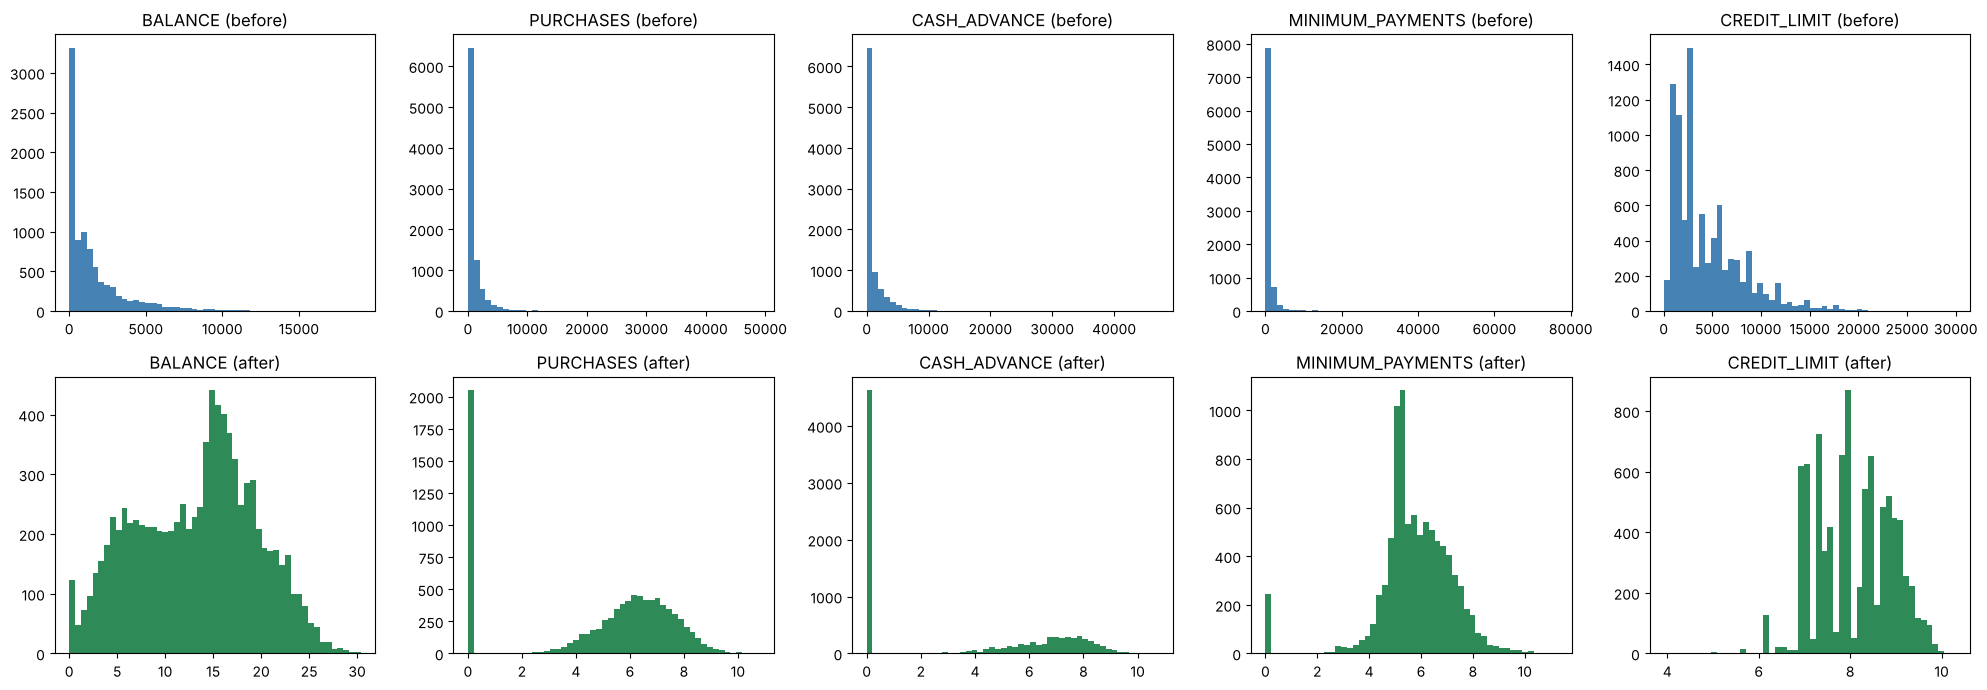

In [11]:
# skewness before vs after
transformed_cols = ['BALANCE'] + log_cols
skew_table = pd.DataFrame({'skew_before': data_before[transformed_cols].skew(),
                           'skew_after': data[transformed_cols].skew()}).round(2)
display(skew_table)

# histograms: before (top row) vs after (bottom row)
show = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'MINIMUM_PAYMENTS', 'CREDIT_LIMIT']
fig, axes = plt.subplots(2, len(show), figsize=(20, 7))
for j, col in enumerate(show):
    axes[0, j].hist(data_before[col], bins=50, color='steelblue')
    axes[0, j].set_title(col + ' (before)')
    axes[1, j].hist(data[col], bins=50, color='seagreen')
    axes[1, j].set_title(col + ' (after)')
plt.tight_layout()
plt.show()

**What changed:** skewness dropped from the range 1.5 to 13.8 down to roughly between -1 and +1 for most transformed features (e.g. `PURCHASES` 8.14 -> -0.76, `BALANCE` 2.39 -> -0.12, `CASH_ADVANCE` 5.17 -> 0.26). The Yeo-Johnson lambda for `BALANCE` is about 0.2, i.e. close to a log-type transform.

**Two things to be aware of:**
* A log transform cannot remove exact zeros: the spikes at 0 in `PURCHASES` (~2,000 customers) and `CASH_ADVANCE` (~4,600 customers) remain. These are real behaviour (customers who never buy / never take cash), not skew, and they are useful for clustering.
* `PAYMENTS` and `MINIMUM_PAYMENTS` still show a negative skew (about -1.78 and -1.18). Exactly 240 customers have a payment of 0 and, after our imputation, a minimum payment of 0. They stay at 0 while most other customers land well above 0 after the log, which creates a tail on the left instead of the right.

The columns we did not transform (`BALANCE_FREQUENCY`, `TENURE`, etc.) keep their original shape.

Now we drop CUST_ID column, then normalize the input values using StandardScaler().

In [12]:
# drop ID column
data = data.drop(columns=['CUST_ID'])

# normalize values
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)
data_scaled.shape

(8950, 17)

In [13]:
data_imputed = pd.DataFrame(data_scaled, columns=data.columns)

We should now be good to go for clustering.

# Clustering

## Correlation Check

<Axes: >

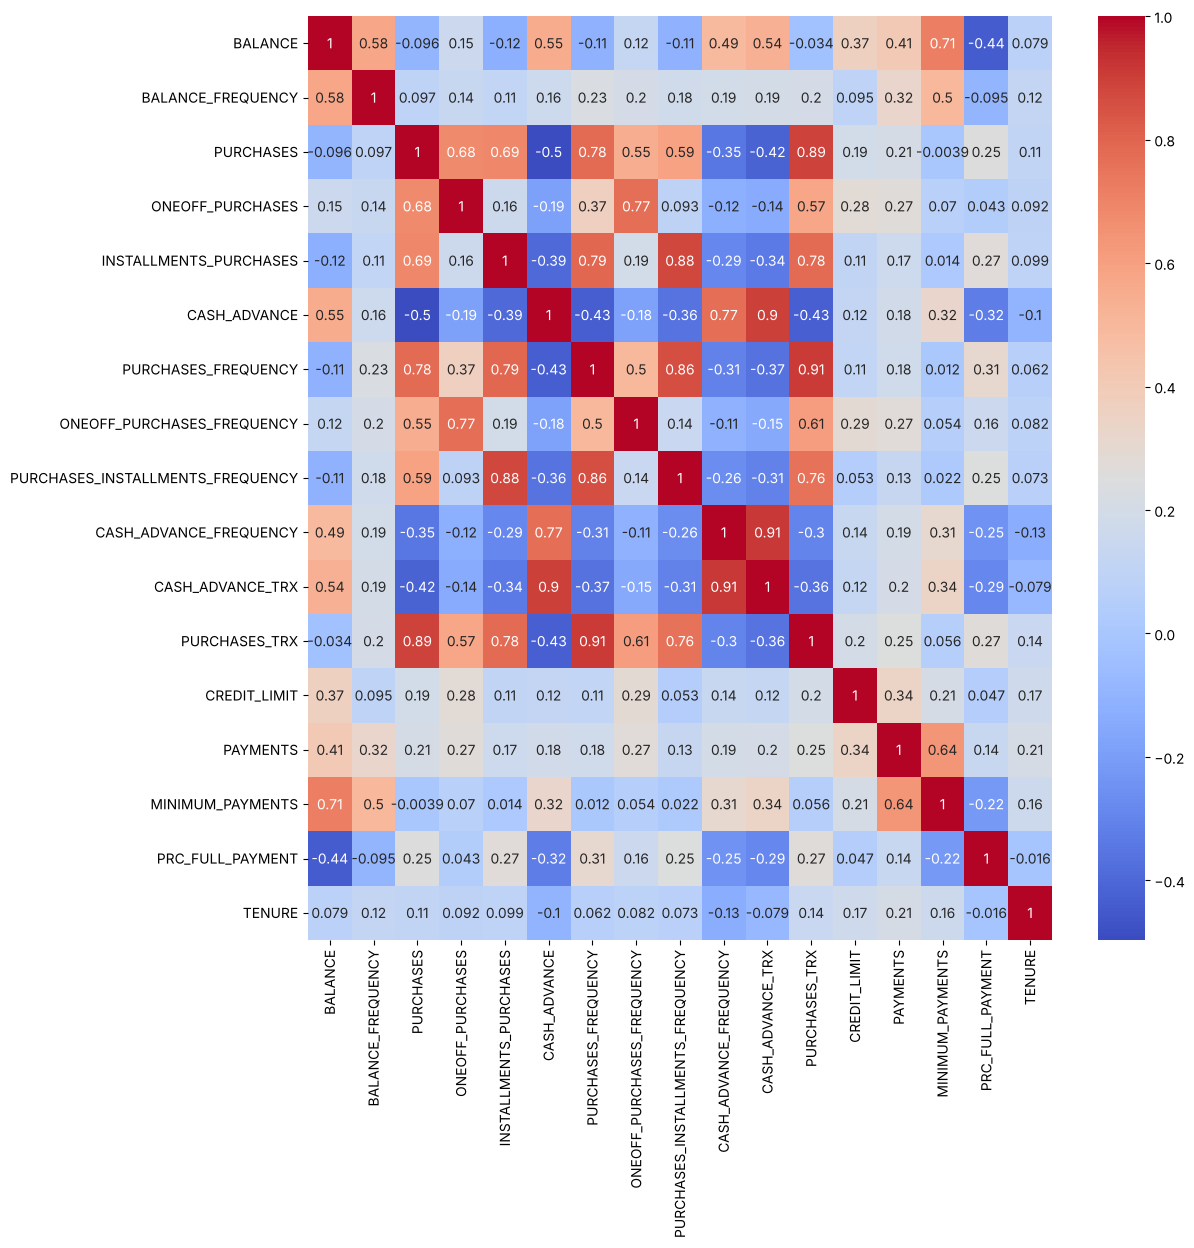

In [14]:
plt.figure(figsize = (12, 12))
sns.heatmap(data_imputed.corr(), annot=True, cmap='coolwarm', 
            xticklabels=data_imputed.columns,
            yticklabels=data_imputed.columns)

In [15]:
# strongly correlated feature pairs (|r| > 0.7) after the transformations
corr = data_imputed.corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename('correlation').reset_index())
pairs.columns = ['feature_1', 'feature_2', 'correlation']
pairs[pairs['correlation'].abs() > 0.7].sort_values('correlation', ascending=False).reset_index(drop=True)

,feature_1,feature_2,correlation
0,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,0.912540
1,PURCHASES_FREQUENCY,PURCHASES_TRX,0.909024
2,CASH_ADVANCE,CASH_ADVANCE_TRX,0.898398
3,PURCHASES,PURCHASES_TRX,0.888988
4,INSTALLMENTS_PURCHASES,PURCHASES_INSTALLMENTS_FREQUENCY,0.878672
5,PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,0.862934
6,INSTALLMENTS_PURCHASES,PURCHASES_FREQUENCY,0.794784
7,INSTALLMENTS_PURCHASES,PURCHASES_TRX,0.782683
8,PURCHASES,PURCHASES_FREQUENCY,0.781750
9,CASH_ADVANCE,CASH_ADVANCE_FREQUENCY,0.770260


After the transformations, 13 feature pairs have a correlation above 0.7. They are mostly pairs that describe the same behaviour twice: how often vs how many times (`PURCHASES_FREQUENCY`/`PURCHASES_TRX` 0.91, `CASH_ADVANCE_FREQUENCY`/`CASH_ADVANCE_TRX` 0.91), amount vs number of transactions (`CASH_ADVANCE`/`CASH_ADVANCE_TRX` 0.90, `PURCHASES`/`PURCHASES_TRX` 0.89), and `BALANCE`/`MINIMUM_PAYMENTS` (0.71). This heavy overlap means the 17 features contain much less than 17 independent pieces of information, which is exactly the situation PCA is designed for.

## Clustering using K-Means

In this section we will perform K-Means clustering on the data and check the clustering metrics (inertia, silhouette scores).

### Inertia Plot

First, we make the inertia plot:

In [16]:
# inertia plotter function
def inertia_plot(clust, X, start = 2, stop = 20):
    inertia = []
    for x in range(start,stop):
        km = clust(n_clusters = x, random_state = 42, n_init = 10)
        labels = km.fit_predict(X)
        inertia.append(km.inertia_)
    plt.figure(figsize = (12,6))
    plt.plot(range(start,stop), inertia, marker = 'o')
    plt.xlabel('Number of Clusters')
    plt.ylabel('Inertia')
    plt.title('Inertia plot with K')
    plt.xticks(list(range(start, stop)))
    plt.show()

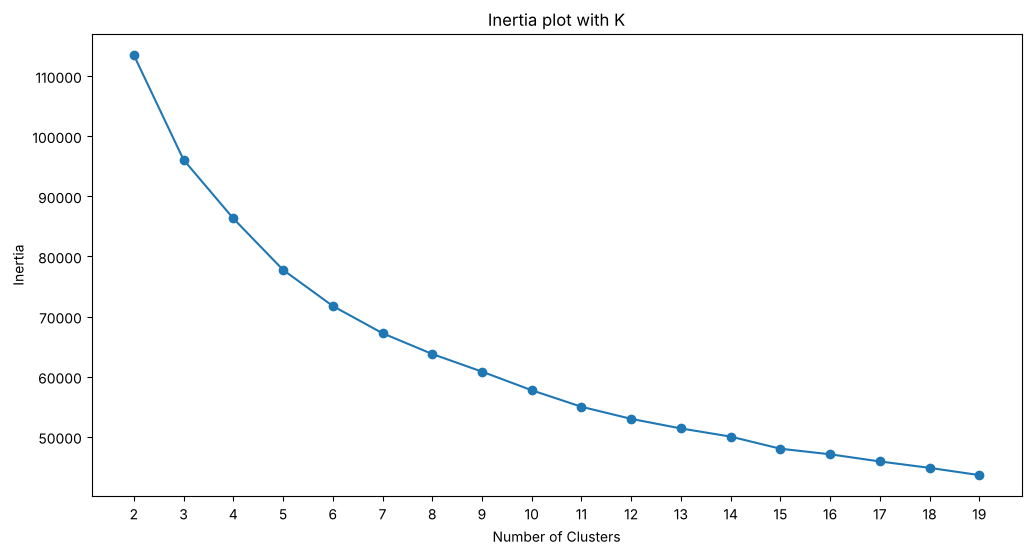

In [17]:
inertia_plot(KMeans, data_imputed)

After the transformations the inertia curve is smooth. There is only a mild bend around 5-6 clusters and no sharp elbow, so we keep 6 clusters, as in the original analysis.

### Silhouette Scores

Silhouette analysis can be used to study the separation distance between the resulting clusters. The silhouette plot displays a measure of how close each point in one cluster is to points in the neighboring clusters and thus provides a way to assess parameters like number of clusters visually. This measure has a range of [-1, 1].

We will now check the silhouette scores for different numbers of clusters. 

In [18]:
def silh_samp_cluster(clust,  X, start=2, stop=5, metric = 'euclidean'):
    # taken from sebastian Raschkas book Python Machine Learning second edition
    for x in range(start, stop):
        km = clust(n_clusters = x, random_state = 42, n_init = 10)
        y_km = km.fit_predict(X)
        cluster_labels = np.unique(y_km)
        n_clusters = cluster_labels.shape[0]
        silhouette_vals = silhouette_samples(X, y_km, metric = metric)
        y_ax_lower, y_ax_upper =0,0
        yticks = []
        for i, c in enumerate(cluster_labels):
            c_silhouette_vals = silhouette_vals[y_km == c]
            c_silhouette_vals.sort()
            y_ax_upper += len(c_silhouette_vals)
            color = cm.jet(float(i)/n_clusters)
            plt.barh(range(y_ax_lower, y_ax_upper),
                    c_silhouette_vals,
                    height=1.0,
                    edgecolor='none',
                    color = color)
            yticks.append((y_ax_lower + y_ax_upper)/2.)
            y_ax_lower+= len(c_silhouette_vals)

        silhouette_avg = np.mean(silhouette_vals)
        plt.axvline(silhouette_avg,
                   color = 'red',
                   linestyle = "--")
        plt.yticks(yticks, cluster_labels+1)
        plt.ylabel("cluster")
        plt.xlabel('Silhouette Coefficient')
        plt.title('Silhouette for ' + str(x) + " Clusters")
        plt.show()

In [19]:
for x in range(2, 7):
    alg = KMeans(n_clusters = x, random_state = 42, n_init = 10)
    label = alg.fit_predict(data_imputed)
    print('Silhouette-Score for', x,  'Clusters: ', silhouette_score(data_imputed, label))

Silhouette-Score for 2 Clusters:  0.25382794457341795


Silhouette-Score for 3 Clusters:  0.22310454368783927


Silhouette-Score for 4 Clusters:  0.2202173236363026


Silhouette-Score for 5 Clusters:  0.2207094025245277


Silhouette-Score for 6 Clusters:  0.21957253229250787


Silhouette plots:

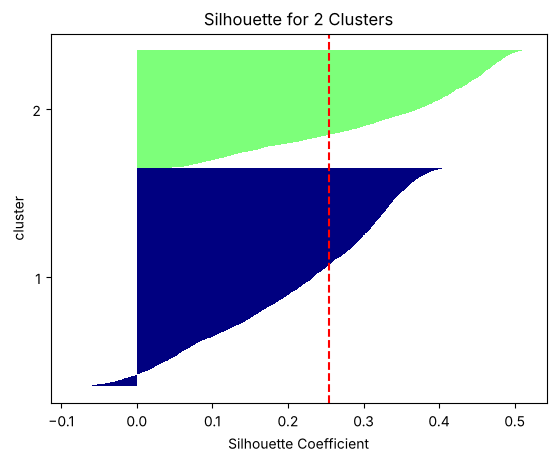

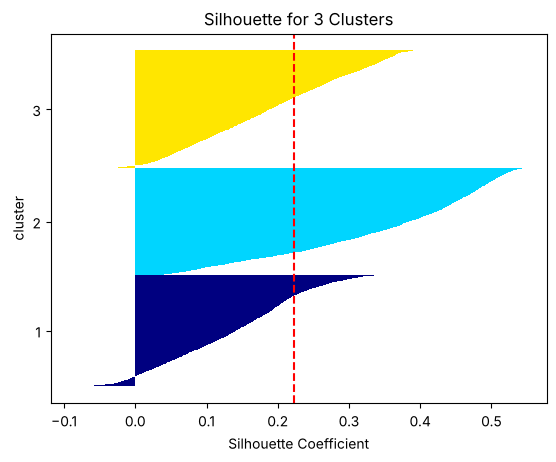

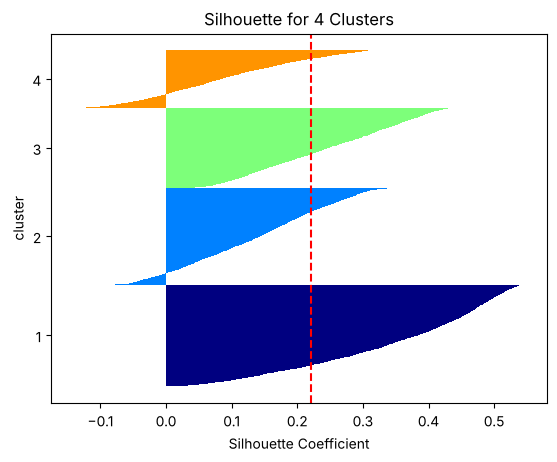

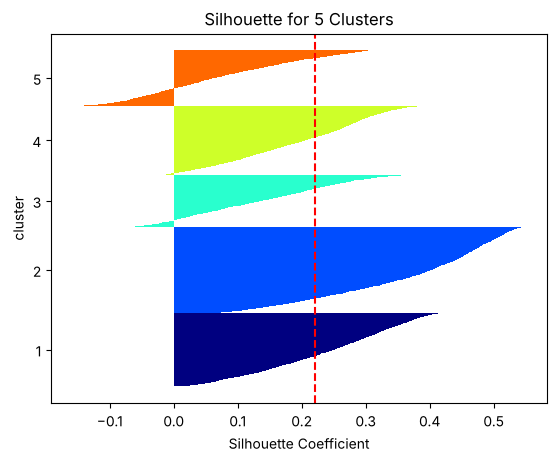

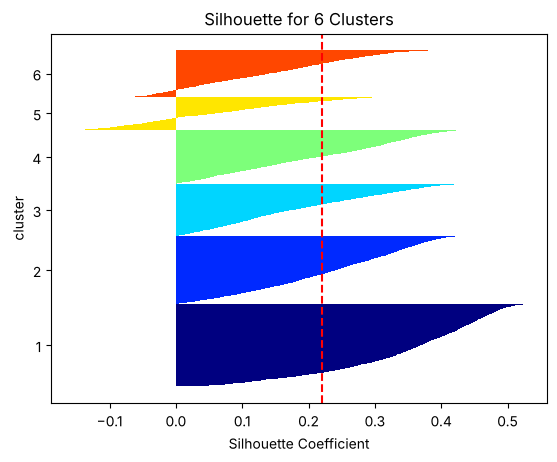

In [20]:
silh_samp_cluster(KMeans, data_imputed, stop=7)

Even after the skewness correction, K-Means on all 17 features is still not performing well: the silhouette scores are low (about 0.25 for 2 clusters and about 0.22 for 3-6 clusters, where 1 would be perfect), the inertia remains high and there is no clear elbow. The transformations give a modest gain (quantified in the *Before vs After* section below), but they do not solve the problem. A likely reason is that many of the 17 features are strongly correlated and repeat the same information, so the clusters are blurred in 17 dimensions. Let's apply feature extraction with PCA to improve clustering.

## Feature Extraction with PCA

### Clustering Metrics

Now we will apply PCA to improve clustering. We should be able to see lower inertias and higher silhouette scores after feature extraction.

### Choosing the number of components: retain 90% of the variance

Instead of guessing 2, 3 or 4 components, we let the data decide: we keep the smallest number of principal components whose cumulative explained variance reaches **90%**.

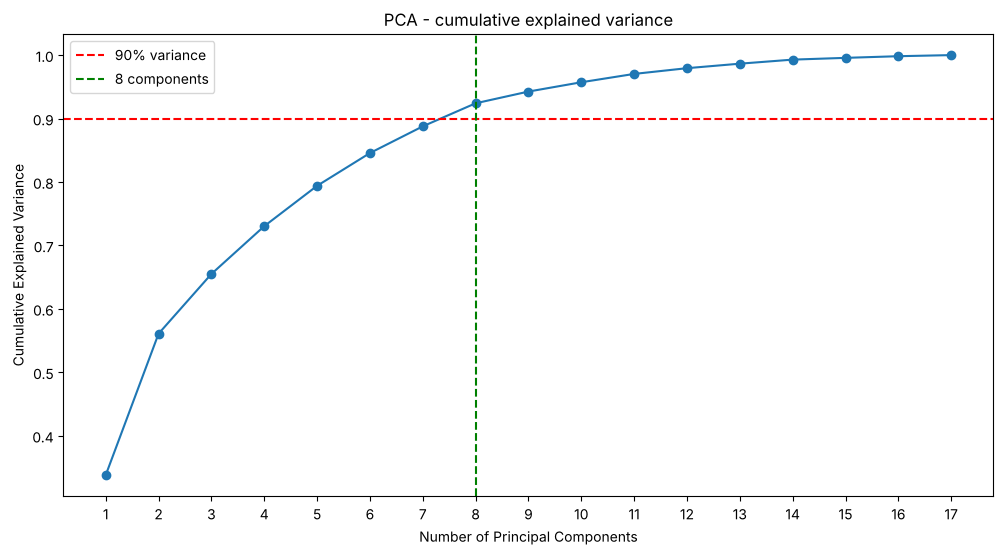

Components needed for 90% variance: 8
Variance retained with 8 components: 0.9241


In [21]:
pca_full = PCA(random_state = 42).fit(data_imputed)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_comp_90 = int(np.argmax(cum_var >= 0.90) + 1)

plt.figure(figsize = (12, 6))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker = 'o')
plt.axhline(0.90, color = 'red', linestyle = '--', label = '90% variance')
plt.axvline(n_comp_90, color = 'green', linestyle = '--', label = str(n_comp_90) + ' components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - cumulative explained variance')
plt.xticks(range(1, len(cum_var) + 1))
plt.legend()
plt.show()

print('Components needed for 90% variance:', n_comp_90)
print('Variance retained with', n_comp_90, 'components:', round(cum_var[n_comp_90 - 1], 4))

In [22]:
# PCA that keeps 90% of the variance (sklearn picks the number of components)
pca = PCA(n_components = 0.90, random_state = 42)
data_pca = pca.fit_transform(data_imputed)
print('Shape after PCA:', data_pca.shape)
print('Explained variance ratio per PC:', pca.explained_variance_ratio_.round(3))

Shape after PCA: (8950, 8)
Explained variance ratio per PC: [0.338 0.223 0.094 0.075 0.064 0.052 0.042 0.036]


In [23]:
# display clustering metrics on the PCA data (90% variance)
print("PCA with # of components: ", pca.n_components_)
for x in range(2, 7):
    alg = KMeans(n_clusters = x, random_state = 42, n_init = 10)
    label = alg.fit_predict(data_pca)
    print('Silhouette-Score for', x,  'Clusters: ', silhouette_score(data_pca, label) , '       Inertia: ',alg.inertia_)

PCA with # of components:  8


Silhouette-Score for 2 Clusters:  0.2738219106995519        Inertia:  101973.35199409709


Silhouette-Score for 3 Clusters:  0.24307913871684145        Inertia:  84753.99091903104


Silhouette-Score for 4 Clusters:  0.24076573288382372        Inertia:  75020.0752091022


Silhouette-Score for 5 Clusters:  0.243543447091048        Inertia:  66768.44627169323


Silhouette-Score for 6 Clusters:  0.24150410222203184        Inertia:  61054.24055158434


Retaining 90% of the variance requires **8 principal components**. With 8 components, the silhouette score is about 0.27 for 2 clusters and stays at about 0.24 for 3-6 clusters, while the inertia falls steadily. Silhouette does not strongly favour one value of k, so, as in the original analysis, 5-6 clusters remain a sensible choice.

Note: these silhouette values are *lower* than the ones for 2 components in the original notebook (about 0.38-0.46). That is not a fair comparison: with 2 components you throw away more than half of the variance and the points look neatly separated in 2-D, whereas 8 dimensions keep 90% of the information but distances are naturally less contrasting. The *Before vs After* section compares the two set-ups on common ground.

## Visualization

Text(0, 0.5, 'PC2')

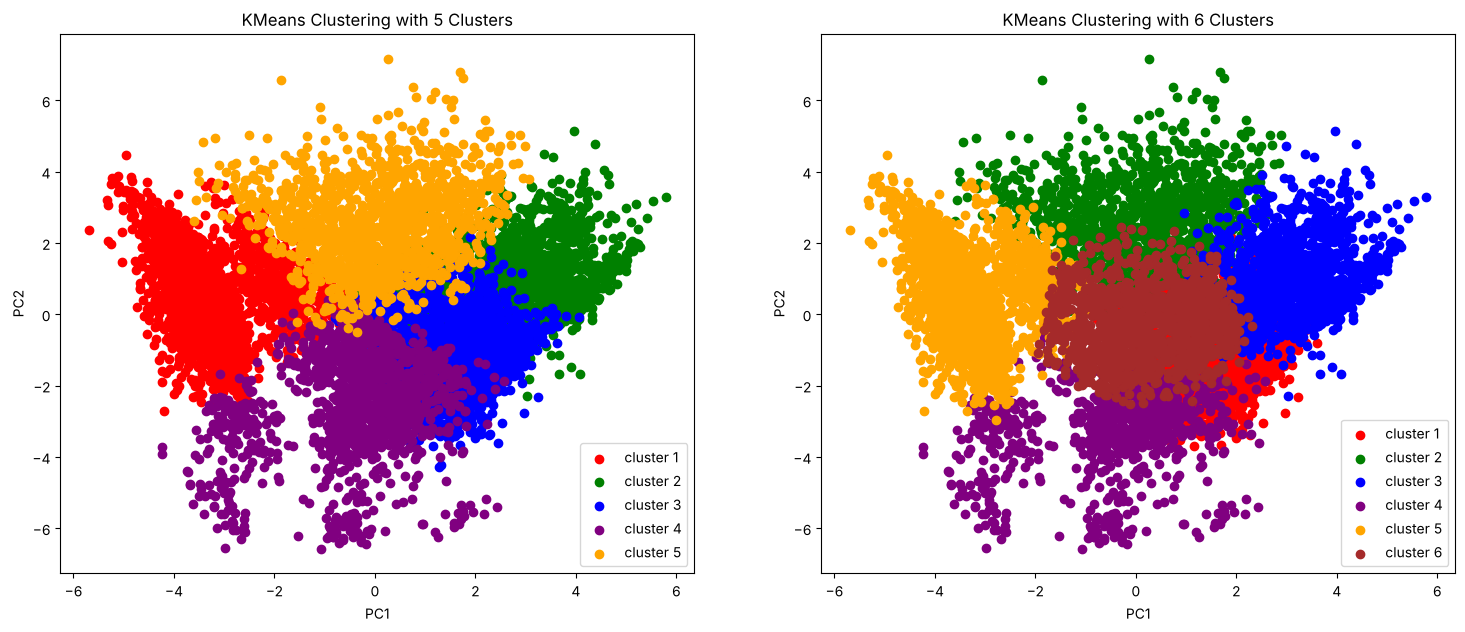

In [24]:
data_p = pd.DataFrame(data_pca[:, :2])   # only PC1 & PC2 are plotted; clustering uses all retained PCs
preds = pd.Series(KMeans(n_clusters = 5, random_state = 42, n_init = 10).fit_predict(data_pca))
data_p = pd.concat([data_p, preds], axis =1)
data_p.columns = [0,1,'target']

fig = plt.figure(figsize = (18, 7))
colors = ['red', 'green', 'blue', 'purple', 'orange', 'brown']
plt.subplot(121)
plt.scatter(data_p[data_p['target']==0].iloc[:,0], data_p[data_p.target==0].iloc[:,1], c = colors[0], label = 'cluster 1')
plt.scatter(data_p[data_p['target']==1].iloc[:,0], data_p[data_p.target==1].iloc[:,1], c = colors[1], label = 'cluster 2')
plt.scatter(data_p[data_p['target']==2].iloc[:,0], data_p[data_p.target==2].iloc[:,1], c = colors[2], label = 'cluster 3')
plt.scatter(data_p[data_p['target']==3].iloc[:,0], data_p[data_p.target==3].iloc[:,1], c = colors[3], label = 'cluster 4')
plt.scatter(data_p[data_p['target']==4].iloc[:,0], data_p[data_p.target==4].iloc[:,1], c = colors[4], label = 'cluster 5')
plt.legend()
plt.title('KMeans Clustering with 5 Clusters')
plt.xlabel('PC1')
plt.ylabel('PC2')


data_p = pd.DataFrame(data_pca[:, :2])   # only PC1 & PC2 are plotted; clustering uses all retained PCs
preds = pd.Series(KMeans(n_clusters = 6, random_state = 42, n_init = 10).fit_predict(data_pca))
data_p = pd.concat([data_p, preds], axis =1)
data_p.columns = [0,1,'target']

plt.subplot(122)
plt.scatter(data_p[data_p['target']==0].iloc[:,0], data_p[data_p.target==0].iloc[:,1], c = colors[0], label = 'cluster 1')
plt.scatter(data_p[data_p['target']==1].iloc[:,0], data_p[data_p.target==1].iloc[:,1], c = colors[1], label = 'cluster 2')
plt.scatter(data_p[data_p['target']==2].iloc[:,0], data_p[data_p.target==2].iloc[:,1], c = colors[2], label = 'cluster 3')
plt.scatter(data_p[data_p['target']==3].iloc[:,0], data_p[data_p.target==3].iloc[:,1], c = colors[3], label = 'cluster 4')
plt.scatter(data_p[data_p['target']==4].iloc[:,0], data_p[data_p.target==4].iloc[:,1], c = colors[4], label = 'cluster 5')
plt.scatter(data_p[data_p['target']==5].iloc[:,0], data_p[data_p.target==5].iloc[:,1], c = colors[5], label = 'cluster 6')
plt.legend()
plt.title('KMeans Clustering with 6 Clusters')
plt.xlabel('PC1')
plt.ylabel('PC2')

The clustering uses all 8 retained components, but only 2 can be drawn, and PC1 + PC2 hold just 56% of the variance (34% + 22%). The overlap seen in this 2-D picture therefore does not mean the clusters overlap in the full 8-D space. K-Means on the 8 PCs gives well-balanced groups (with 6 clusters, between about 900 and 2,200 customers each). Let's try other clustering models as well!

## Agglomerative Hierarchical Clustering with PCA

Text(0, 0.5, 'PC2')

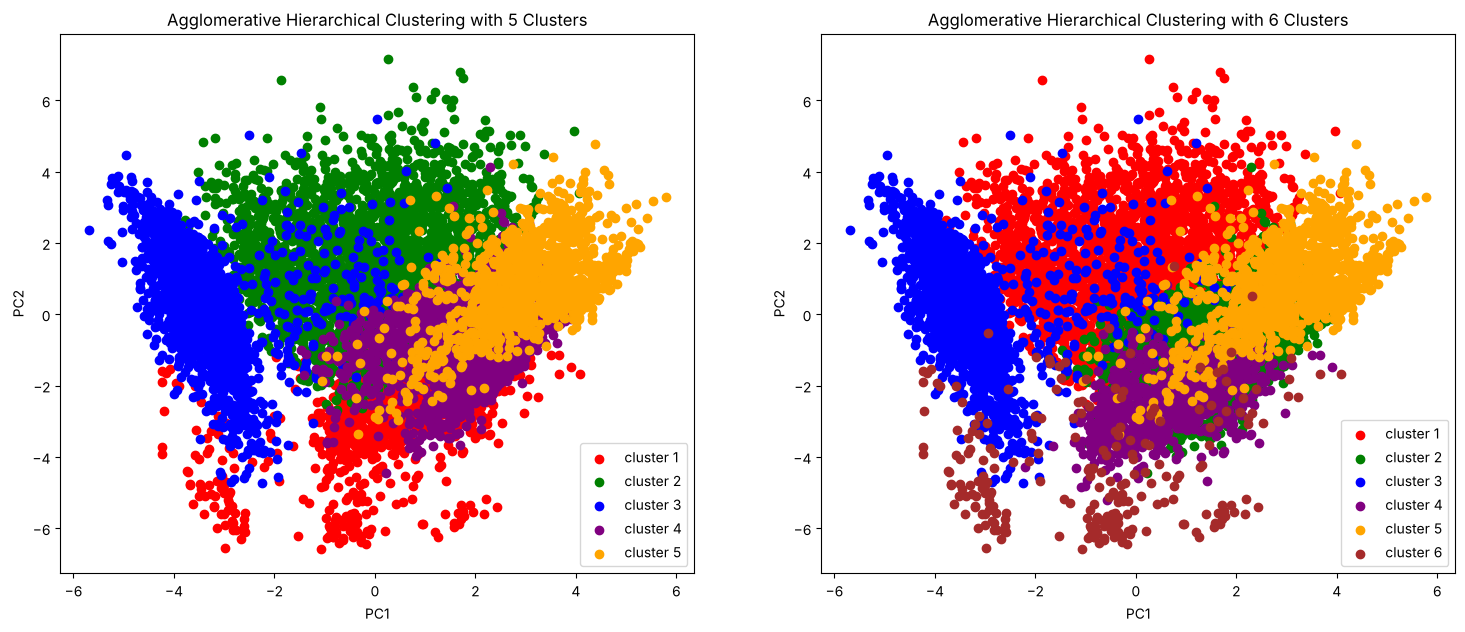

In [25]:
data_p = pd.DataFrame(data_pca[:, :2])   # only PC1 & PC2 are plotted; clustering uses all retained PCs
preds = pd.Series(AgglomerativeClustering(n_clusters = 5,).fit_predict(data_pca))
data_p = pd.concat([data_p, preds], axis =1)
data_p.columns = [0,1,'target']

fig = plt.figure(figsize = (18, 7))
colors = ['red', 'green', 'blue', 'purple', 'orange', 'brown']
plt.subplot(121)
plt.scatter(data_p[data_p['target']==0].iloc[:,0], data_p[data_p.target==0].iloc[:,1], c = colors[0], label = 'cluster 1')
plt.scatter(data_p[data_p['target']==1].iloc[:,0], data_p[data_p.target==1].iloc[:,1], c = colors[1], label = 'cluster 2')
plt.scatter(data_p[data_p['target']==2].iloc[:,0], data_p[data_p.target==2].iloc[:,1], c = colors[2], label = 'cluster 3')
plt.scatter(data_p[data_p['target']==3].iloc[:,0], data_p[data_p.target==3].iloc[:,1], c = colors[3], label = 'cluster 4')
plt.scatter(data_p[data_p['target']==4].iloc[:,0], data_p[data_p.target==4].iloc[:,1], c = colors[4], label = 'cluster 5')
plt.legend()
plt.title('Agglomerative Hierarchical Clustering with 5 Clusters')
plt.xlabel('PC1')
plt.ylabel('PC2')


data_p = pd.DataFrame(data_pca[:, :2])   # only PC1 & PC2 are plotted; clustering uses all retained PCs
preds = pd.Series(AgglomerativeClustering(n_clusters = 6,).fit_predict(data_pca))
data_p = pd.concat([data_p, preds], axis =1)
data_p.columns = [0,1,'target']

plt.subplot(122)
plt.scatter(data_p[data_p['target']==0].iloc[:,0], data_p[data_p.target==0].iloc[:,1], c = colors[0], label = 'cluster 1')
plt.scatter(data_p[data_p['target']==1].iloc[:,0], data_p[data_p.target==1].iloc[:,1], c = colors[1], label = 'cluster 2')
plt.scatter(data_p[data_p['target']==2].iloc[:,0], data_p[data_p.target==2].iloc[:,1], c = colors[2], label = 'cluster 3')
plt.scatter(data_p[data_p['target']==3].iloc[:,0], data_p[data_p.target==3].iloc[:,1], c = colors[3], label = 'cluster 4')
plt.scatter(data_p[data_p['target']==4].iloc[:,0], data_p[data_p.target==4].iloc[:,1], c = colors[4], label = 'cluster 5')
plt.scatter(data_p[data_p['target']==5].iloc[:,0], data_p[data_p.target==5].iloc[:,1], c = colors[5], label = 'cluster 6')
plt.legend()
plt.title('Agglomerative Hierarchical Clustering with 6 Clusters')
plt.xlabel('PC1')
plt.ylabel('PC2')

# Did the Additions Help? Before vs After

To judge the changes fairly we re-run both algorithms, K-Means and Agglomerative (6 clusters each), in four set-ups:

1. **Original** pre-processing (scaling only), no PCA
2. **New** pre-processing (Yeo-Johnson + log + scaling), no PCA
3. **Original** approach: scaled data -> PCA with 2 components
4. **New** approach: transformed + scaled data -> PCA keeping 90% variance

Silhouette scores computed in *different* spaces (2-D vs 8-D) are not directly comparable, so we also score every set of labels in one *common* space (the 17 transformed + scaled features), and report how much variance PCA kept and how balanced the cluster sizes are.

In [26]:
from sklearn.metrics import davies_bouldin_score

X_old = StandardScaler().fit_transform(data_before)          # original pre-processing
X_new = data_imputed.values                                   # new pre-processing
pca_old = PCA(n_components = 2, random_state = 42).fit(X_old) # original: 2 components
Z_old = pca_old.transform(X_old)

setups = {'1. Original, no PCA': (X_old, 1.0),
          '2. New, no PCA': (X_new, 1.0),
          '3. Original + PCA (2 comps)': (Z_old, pca_old.explained_variance_ratio_.sum()),
          '4. New + PCA (90% var)': (data_pca, pca.explained_variance_ratio_.sum())}
models = {'KMeans': lambda: KMeans(n_clusters = 6, random_state = 42, n_init = 10),
          'Agglomerative': lambda: AgglomerativeClustering(n_clusters = 6)}

rows = []
for m, make in models.items():
    for s, (X, var_kept) in setups.items():
        lab = make().fit_predict(X)
        sizes = np.bincount(lab)
        rows.append({'Model': m, 'Set-up': s,
                     'Variance kept': round(var_kept, 3),
                     'Silhouette (own space)': round(silhouette_score(X, lab), 3),
                     'Silhouette (common space)': round(silhouette_score(X_new, lab), 3),
                     'Davies-Bouldin (common space, lower=better)': round(davies_bouldin_score(X_new, lab), 2),
                     'Smallest cluster': sizes.min(), 'Largest cluster': sizes.max()})
comparison = pd.DataFrame(rows)
comparison

,Model,Set-up,Variance kept,Silhouette (own space),Silhouette (common space),"Davies-Bouldin (common space, lower=better)",Smallest cluster,Largest cluster
0,KMeans,"1. Original, no PCA",1.000,0.203,0.145,2.03,86,3039
1,KMeans,"2. New, no PCA",1.000,0.220,0.220,1.46,884,2182
2,KMeans,3. Original + PCA (2 comps),0.476,0.388,0.082,2.58,64,3018
3,KMeans,4. New + PCA (90% var),0.924,0.242,0.220,1.46,921,2242
4,Agglomerative,"1. Original, no PCA",1.000,0.157,0.101,1.97,326,2793
5,Agglomerative,"2. New, no PCA",1.000,0.179,0.179,1.77,241,2428
6,Agglomerative,3. Original + PCA (2 comps),0.476,0.328,0.058,1.90,25,4466
7,Agglomerative,4. New + PCA (90% var),0.924,0.176,0.164,1.68,243,2391


In [27]:
# K-Means (6 clusters): share of total variance left unexplained (inertia / total sum of squares)
# Both data sets are standardised, so these two numbers are directly comparable.
for name, X in [('Original, no PCA', X_old), ('New, no PCA', X_new)]:
    km = KMeans(n_clusters = 6, random_state = 42, n_init = 10).fit(X)
    print(name, '-> unexplained variance:', round(km.inertia_ / (X.shape[0] * X.shape[1]), 3))

Original, no PCA -> unexplained variance: 0.557
New, no PCA -> unexplained variance: 0.472


### Verdict: did the changes help, and which model is best?

**Yes, the project is more reliable, but the gain is moderate, and a single silhouette number would hide that.** (Numbers below are from the run shown above. Both the "original" and "new" set-ups use the same imputed data, so the differences come from the transformations and PCA.)

**What clearly improved**
* **Skewness** was removed from the main numeric features (e.g. `PURCHASES` 8.14 -> -0.76, `CASH_ADVANCE` 5.17 -> 0.26), so a handful of extreme customers no longer dominates the distances.
* **K-Means without PCA:** the share of variance left unexplained fell from 55.7% to 47.2%, silhouette rose (0.203 -> 0.220), and Davies-Bouldin improved (2.03 -> 1.46, lower is better). The smallest cluster grew from 86 to 884 customers, so the original solution had one very small cluster.
* **PCA keeps far more information:** 2 components kept only 47.6% of the variance; the 90% rule keeps 92.4% (8 components).
* **K-Means + PCA** produces much more balanced and better-separated groups: the smallest cluster went from 64 to 921 customers; scored in the common space, silhouette rose from 0.082 to 0.220 and Davies-Bouldin fell from 2.58 to 1.46.
* **Agglomerative** also improved: with PCA the smallest cluster grew from 25 to 243 customers and Davies-Bouldin fell from 1.90 to 1.68; without PCA silhouette rose from 0.157 to 0.179 and Davies-Bouldin fell from 1.97 to 1.77.

**What did not improve, or needs a caveat**
* The *own-space* silhouette went **down** with PCA (K-Means about 0.39 -> 0.24, Agglomerative 0.33 -> 0.18). This is mostly a dimensionality effect (2-D vs 8-D), not worse clustering, but you should not present the old scores as being "better".
* The "common space" scores are measured in the transformed feature space, which naturally favours the new pipeline, so treat them as supporting evidence, not proof.
* Absolute silhouette scores of about 0.2 are still low: customer behaviour is more of a continuum than a set of cleanly separated groups, so the segments are useful for marketing but not sharply defined.

**Which model is best? K-Means.** In the new pipeline it beats Agglomerative in every set-up on every measure: with PCA (90% variance) silhouette is 0.242 vs 0.176, common-space silhouette 0.220 vs 0.164 and Davies-Bouldin 1.46 vs 1.68 (lower is better); without PCA it is 0.220 vs 0.179 and 1.46 vs 1.77. Its clusters are also the most balanced (smallest cluster 921 customers vs 243 for Agglomerative). One caveat: silhouette favours compact, round clusters, which is what K-Means produces, so some of its advantage is built into the metric. The margin is still consistent across all the measures we checked.

**Suggested choice:** K-Means with 5-6 clusters on the transformed data (with or without the 90%-variance PCA).

# Exploratory Data Analysis of the Final Model

**Final model: K-Means with 6 clusters on the PCA data (8 principal components that keep 90% of the variance).**

Earlier versions of this section clustered a hand-picked set of 6 columns, which is a *different* model from the one we evaluated above. Here we profile **exactly the clusters produced by the final model**, so every conclusion describes the model we actually chose.

The steps are:
1. Rebuild the final cluster labels and give them stable numbers
2. Cluster sizes
3. Cluster profile table in the original (real-money) units
4. "Fingerprint" heatmap of all 17 features
5. Feature distributions per cluster (box plots)
6. The clusters in PCA space, and what the PCs mean
7. How well-formed is each cluster? (per-cluster silhouette)
8. Pair plots on the key features
9. A deep-dive on every cluster, one by one
10. Summary, marketing strategy and conclusion

## Step 1: Rebuild the final cluster labels

We need three versions of the same table, all with the same row order and the same `cluster` column:

* `df_orig`: the **original units** (from `data_before`). Use it to describe clusters in real money, e.g. "median purchases = 2,390".
* `df_z`: the **transformed + standardized** features (`data_imputed`). Use it for plots, because skewed raw values squash the pictures.
* `df_pc`: the **principal components** (`data_pca`). The model actually clustered in this space.

K-Means gives arbitrary cluster numbers (the cluster called 0 could come out as 3 on another run). To make the numbers meaningful and stable, we **renumber the clusters in increasing order of average PURCHASES**: cluster 0 buys least, cluster 5 buys most.

In [28]:
# 1) the final model: K-Means, 6 clusters, on the 8 PCA components (same settings as above)
final_km = KMeans(n_clusters = 6, random_state = 42, n_init = 10)
raw_labels = final_km.fit_predict(data_pca)
print('Silhouette of the final model (PCA space):', round(silhouette_score(data_pca, raw_labels), 4))

# 2) renumber clusters in order of increasing mean PURCHASES (original units)
order = data_before.groupby(raw_labels)['PURCHASES'].mean().sort_values().index
relabel = {old: new for new, old in enumerate(order)}
labels = pd.Series(raw_labels, name = 'cluster').map(relabel)

# 3) three aligned tables, all carrying the cluster column
df_orig = data_before.copy();                                    df_orig['cluster'] = labels.values
df_z    = data_imputed.copy();                                   df_z['cluster']    = labels.values
df_pc   = pd.DataFrame(data_pca, columns = ['PC' + str(i + 1) for i in range(data_pca.shape[1])])
df_pc['cluster'] = labels.values

# helper features for interpretation (original units)
df_orig['UTILISATION'] = df_orig['BALANCE'] / df_orig['CREDIT_LIMIT']      # share of the limit that is used
print(df_orig.shape, df_z.shape, df_pc.shape)

Silhouette of the final model (PCA space): 0.2415
(8950, 19) (8950, 18) (8950, 9)


**Why this step matters:** every later plot and table is just a different view of the same `cluster` column. If the labels were re-created inconsistently in each cell (as can happen when K-Means is re-run without a seed), the plots would describe different clusterings and the written conclusions would not match them.

## Step 2: Cluster sizes

First question for any segmentation: **how big is each group?** A group with 20 customers cannot support a marketing campaign, and one group holding 80% of the customers means the clustering did not really split the data.

         customers  share %
cluster                    
0             2242     25.1
1              921     10.3
2             1824     20.4
3             1369     15.3
4             1191     13.3
5             1403     15.7


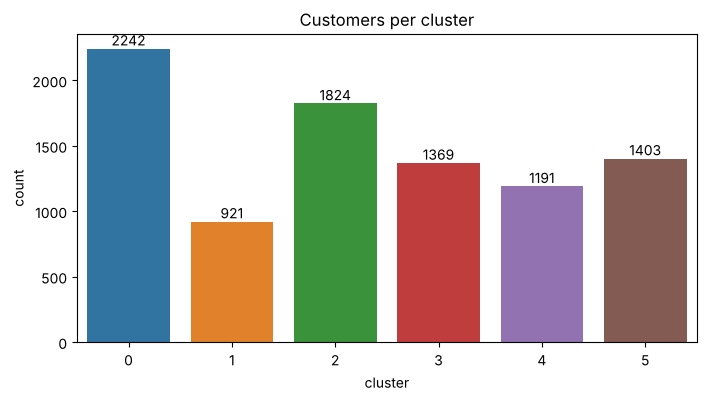

In [29]:
sizes = df_orig['cluster'].value_counts().sort_index()
size_table = pd.DataFrame({'customers': sizes, 'share %': (100 * sizes / len(df_orig)).round(1)})
print(size_table)

plt.figure(figsize = (8, 4))
ax = sns.countplot(x = 'cluster', data = df_orig, palette = 'tab10')
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha = 'center', va = 'bottom')
plt.title('Customers per cluster')
plt.show()

**What we see:** the clusters range from 921 customers (10.3%) to 2,242 (25.1%). No cluster is tiny and none dominates, so every segment is large enough to build a campaign around. That balance comes from clustering in PCA space after removing the skew; extreme spenders no longer get a cluster of their own.

## Step 3: Cluster profile table in original units

Averages can be misleading when data is skewed (a few huge spenders drag the mean up), so we show the **median** (the typical customer) and the **mean** side by side. A big gap between them tells you the cluster contains a few extreme customers.

In [30]:
profile_cols = ['BALANCE', 'CREDIT_LIMIT', 'UTILISATION',
                'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'PURCHASES_TRX', 'PURCHASES_FREQUENCY',
                'CASH_ADVANCE', 'CASH_ADVANCE_TRX', 'CASH_ADVANCE_FREQUENCY',
                'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'BALANCE_FREQUENCY', 'TENURE']

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print('MEDIAN per cluster (typical customer), original units')
display(df_orig.groupby('cluster')[profile_cols].median().round(2).T)
print('MEAN per cluster, original units')
display(df_orig.groupby('cluster')[profile_cols].mean().round(2).T)

MEDIAN per cluster (typical customer), original units


cluster,0,1,2,3,4,5
BALANCE,1617.48,14.37,95.39,843.36,2772.79,722.69
CREDIT_LIMIT,3000.00,2700.00,2000.00,2600.00,5500.00,6500.00
UTILISATION,0.66,0.01,0.05,0.33,0.62,0.15
PURCHASES,0.00,111.30,450.34,466.18,909.30,2390.60
ONEOFF_PURCHASES,0.00,0.00,0.00,400.00,403.38,1364.34
INSTALLMENTS_PURCHASES,0.00,0.00,424.03,0.00,333.28,752.46
PURCHASES_TRX,0.00,2.00,12.00,5.00,14.00,33.00
PURCHASES_FREQUENCY,0.00,0.17,0.92,0.33,0.75,1.00
CASH_ADVANCE,1365.53,0.00,0.00,0.00,2025.44,0.00
CASH_ADVANCE_TRX,4.00,0.00,0.00,0.00,7.00,0.00


MEAN per cluster, original units


cluster,0,1,2,3,4,5
BALANCE,2333.46,114.20,413.24,1110.18,3526.24,1562.30
CREDIT_LIMIT,4172.36,3555.56,2887.26,3785.65,6110.12,7033.98
UTILISATION,0.62,0.04,0.23,0.42,0.61,0.25
PURCHASES,23.94,230.22,640.46,726.42,1441.61,3445.01
ONEOFF_PURCHASES,20.90,147.01,36.16,667.29,823.74,2251.97
INSTALLMENTS_PURCHASES,3.10,83.28,605.22,59.48,618.13,1193.04
PURCHASES_TRX,0.29,3.22,14.51,7.07,23.61,45.46
PURCHASES_FREQUENCY,0.02,0.22,0.82,0.36,0.72,0.92
CASH_ADVANCE,2101.71,227.77,45.92,135.64,2932.47,54.93
CASH_ADVANCE_TRX,6.84,0.66,0.17,0.48,9.99,0.19


## Step 4: The cluster "fingerprint" heatmap

A table of 17 features x 6 clusters is hard to read. Instead we show, for every cluster, the **average z-score** of each feature (using the transformed + standardized data). A z-score of +1 means "one standard deviation above the average customer", so **red = above average, blue = below average**. Because every feature is on the same scale, the colours are directly comparable, and each cluster gets a visual fingerprint.

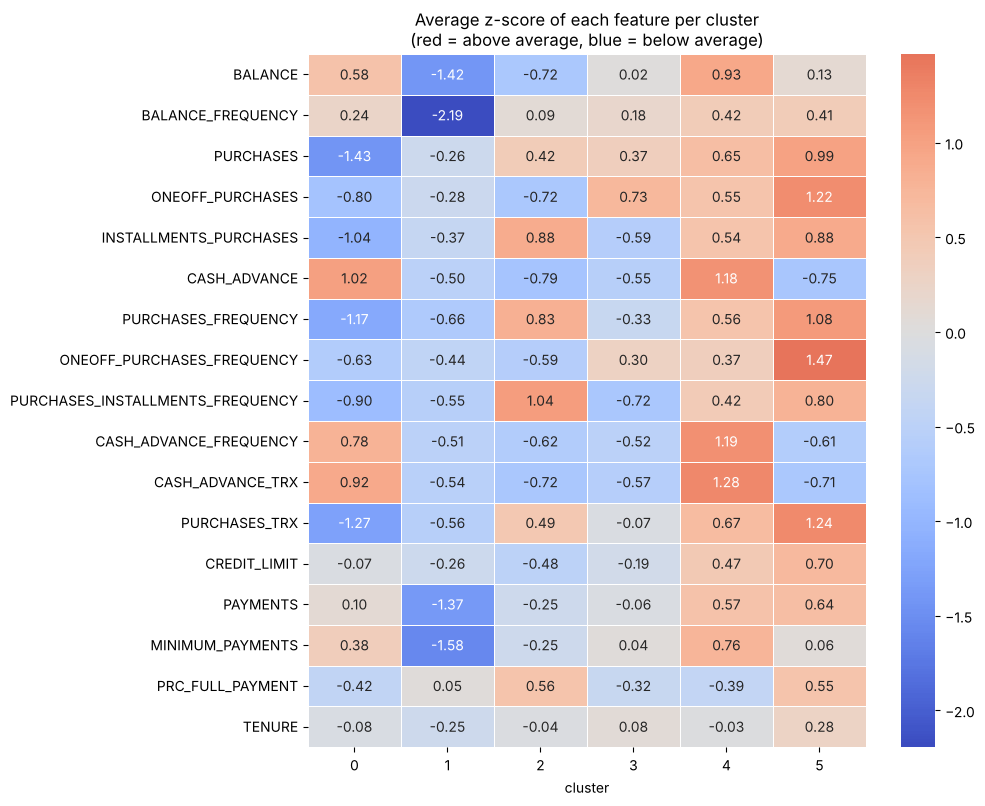

In [31]:
fingerprint = df_z.groupby('cluster').mean().T          # 17 features x 6 clusters
plt.figure(figsize = (9, 9))
sns.heatmap(fingerprint, annot = True, fmt = '.2f', cmap = 'coolwarm', center = 0, linewidths = 0.5)
plt.title('Average z-score of each feature per cluster\n(red = above average, blue = below average)')
plt.show()

**How to read it:** look down a column to describe one cluster, look across a row to see which clusters separate on one feature. Strong signals (about +/-1 or more) are the cluster's identity:
* **Cluster 0:** very low PURCHASES (-1.43) but high CASH_ADVANCE (+1.02)
* **Cluster 1:** very low BALANCE_FREQUENCY (-2.19), BALANCE (-1.42), PAYMENTS (-1.37) and MINIMUM_PAYMENTS (-1.58)
* **Cluster 2:** high installment purchases (+0.88) and installment frequency (+1.04), low cash advance and low one-off purchases
* **Cluster 3:** one-off purchases (+0.73) but low installments (-0.59) and a middling purchase frequency
* **Cluster 4:** the highest CASH_ADVANCE (+1.18) and BALANCE (+0.93), with purchases also above average
* **Cluster 5:** the highest purchases of every kind, especially one-off frequency (+1.47) and purchase transactions (+1.24)

## Step 5: Feature distributions per cluster (box plots)

The heatmap shows only the average. A box plot shows the **spread**: the box is the middle 50% of customers, the line is the median, the dots are unusual customers. If two clusters have the same average but very different spreads, you need the box plot to see it. We plot the transformed (not raw) values so that the boxes are readable.

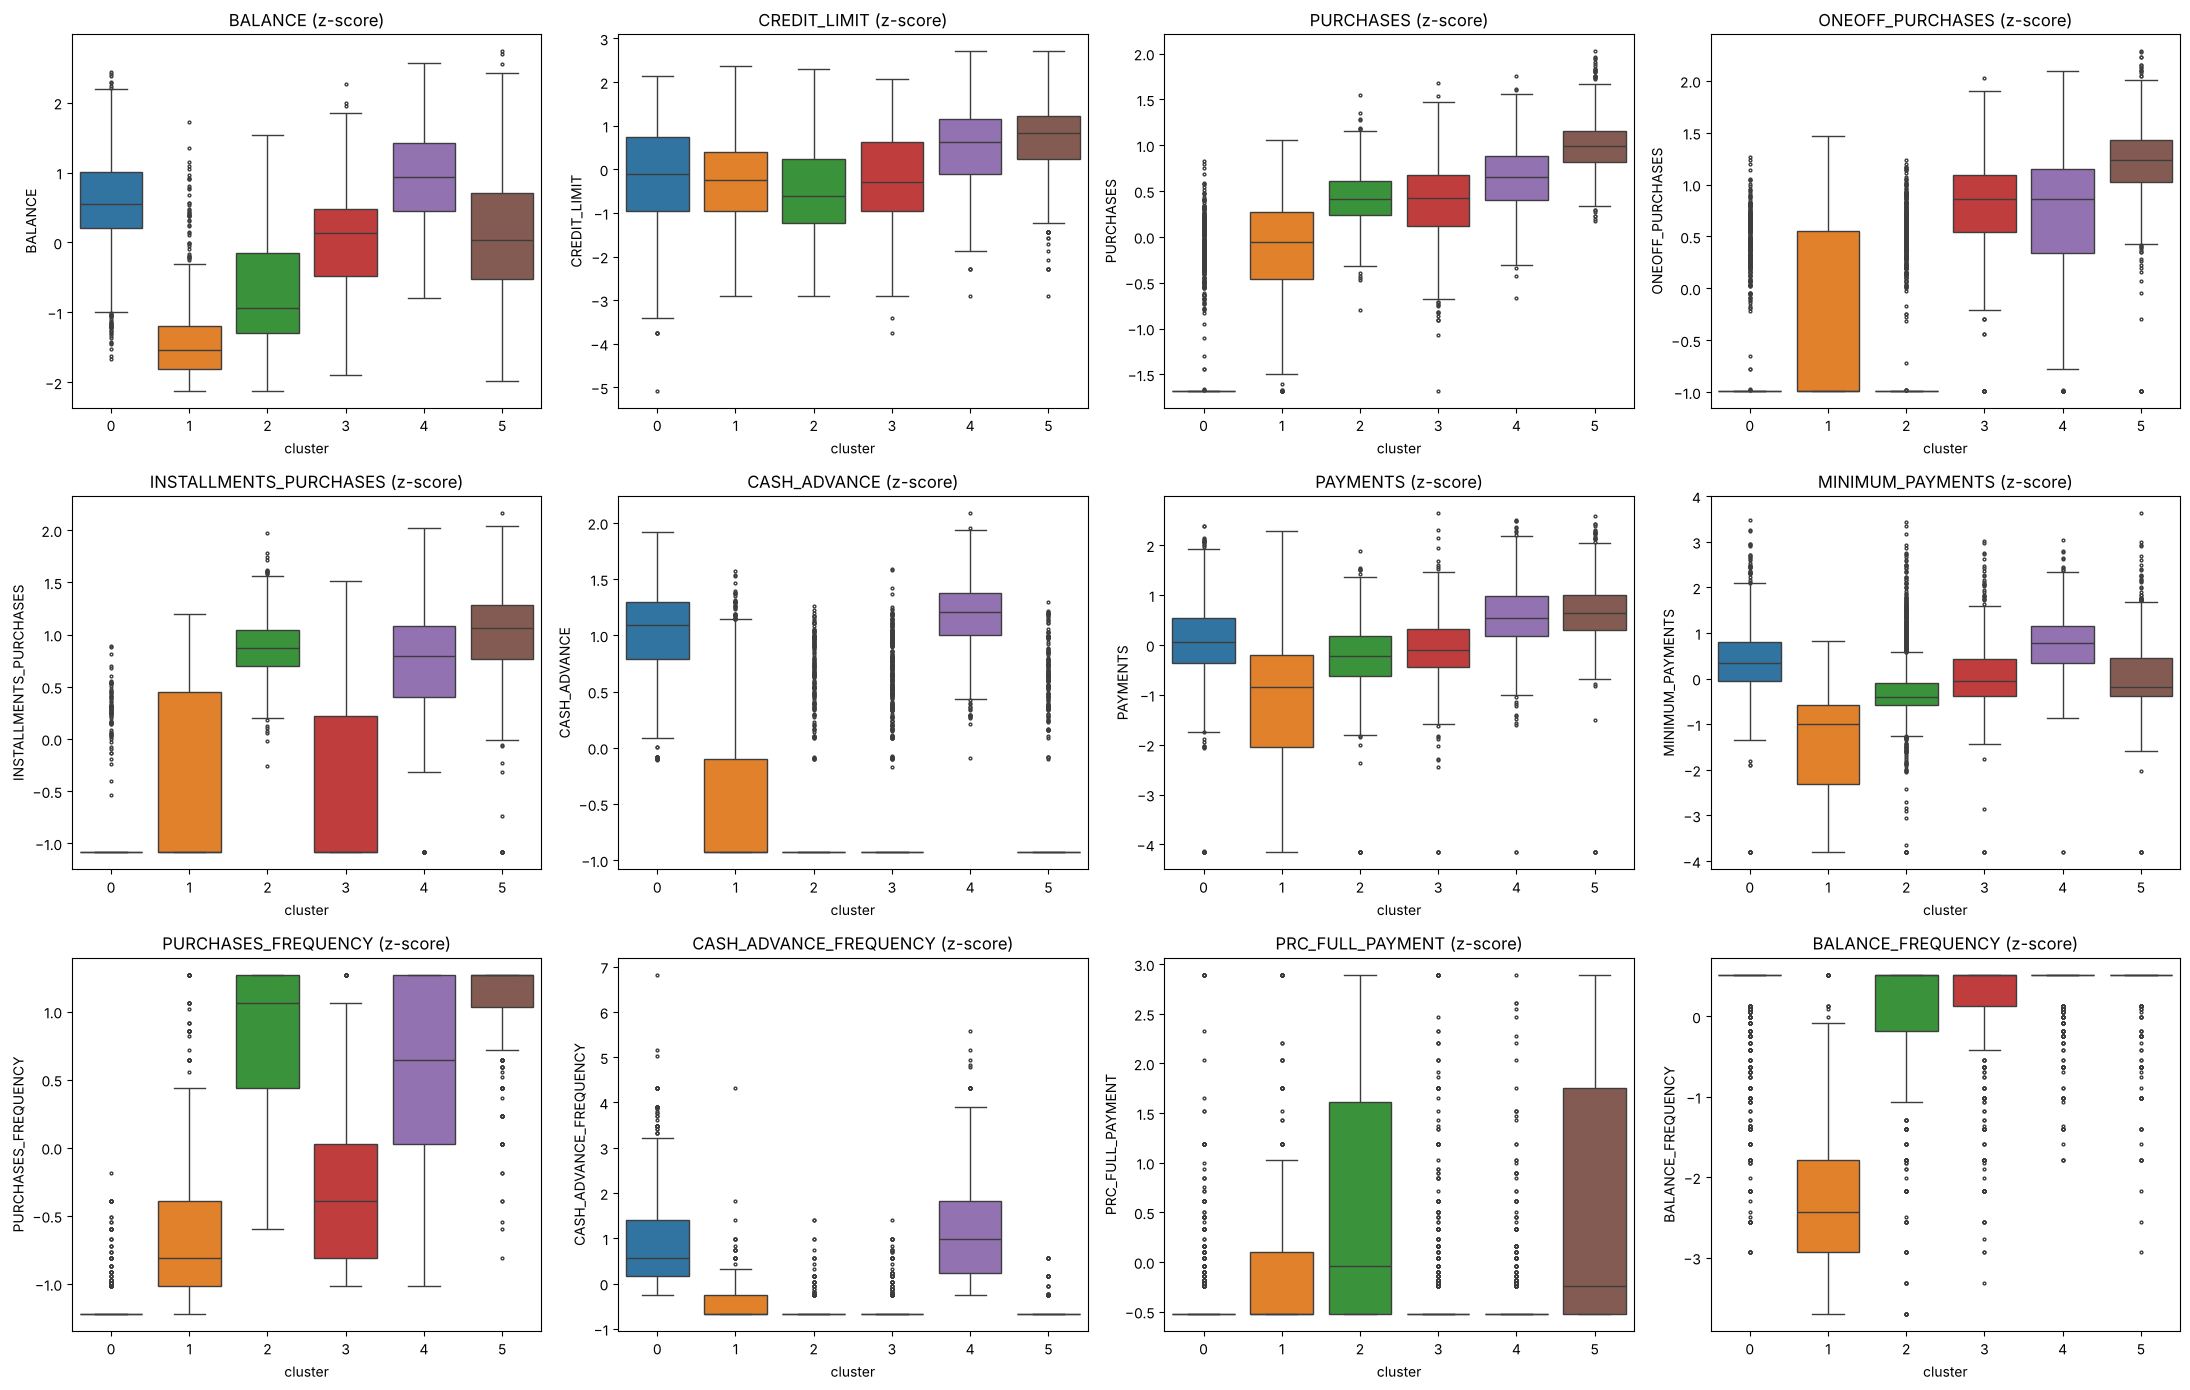

In [32]:
box_cols = ['BALANCE', 'CREDIT_LIMIT', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE',
            'PAYMENTS', 'MINIMUM_PAYMENTS', 'PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'PRC_FULL_PAYMENT', 'BALANCE_FREQUENCY']
fig, axes = plt.subplots(3, 4, figsize = (22, 14))
for ax, col in zip(axes.ravel(), box_cols):
    sns.boxplot(x = 'cluster', y = col, data = df_z, palette = 'tab10', ax = ax, fliersize = 2)
    ax.set_title(col + ' (z-score)')
plt.tight_layout()
plt.show()

## Step 6: The clusters in PCA space, and what the PCs mean

The model clustered the customers in 8 dimensions, but we can draw only 2 or 3. We plot PC1 vs PC2 and PC1 vs PC3, coloured by the final cluster, and mark each cluster's centre. PC1 and PC2 together hold only about 56% of the variance, so **some overlap in these pictures is expected**; it does not mean the clusters overlap in 8-D.

To read the axes we also draw the **loadings**: how strongly each original feature contributes to each PC.

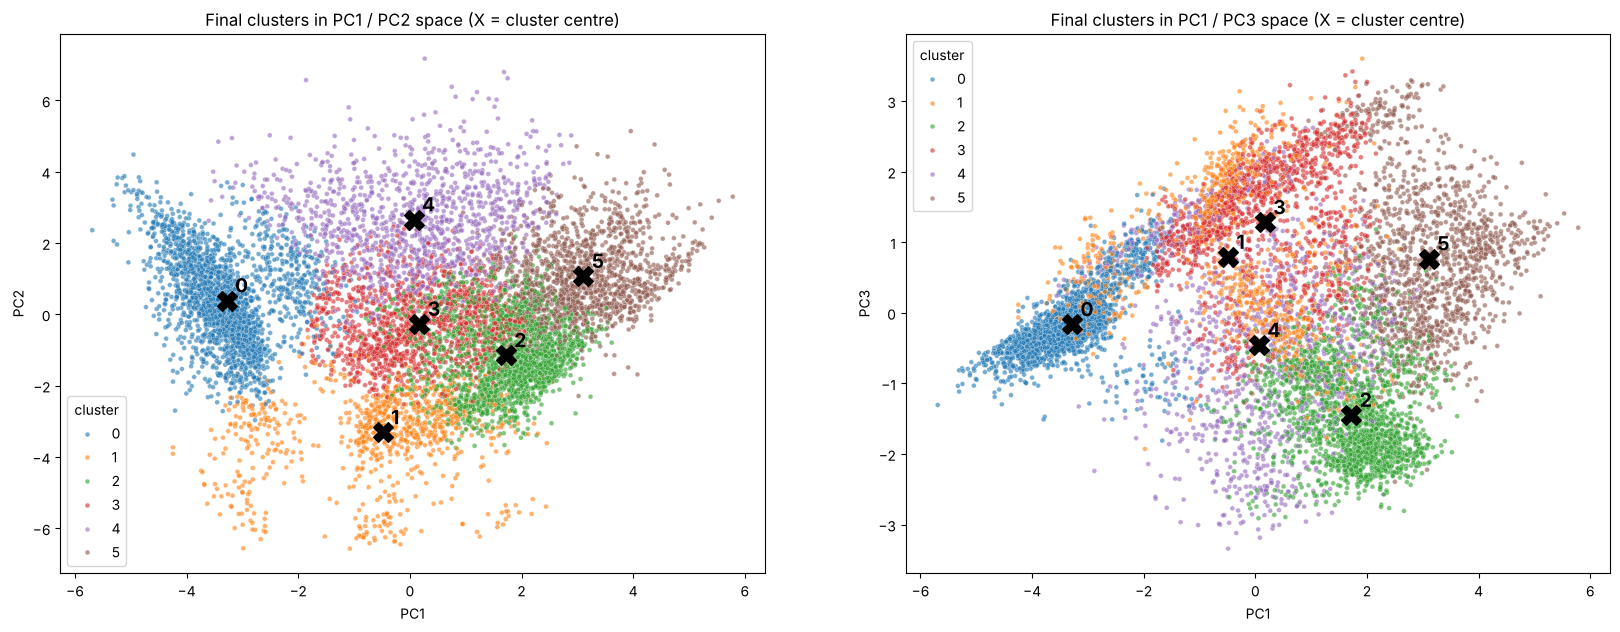

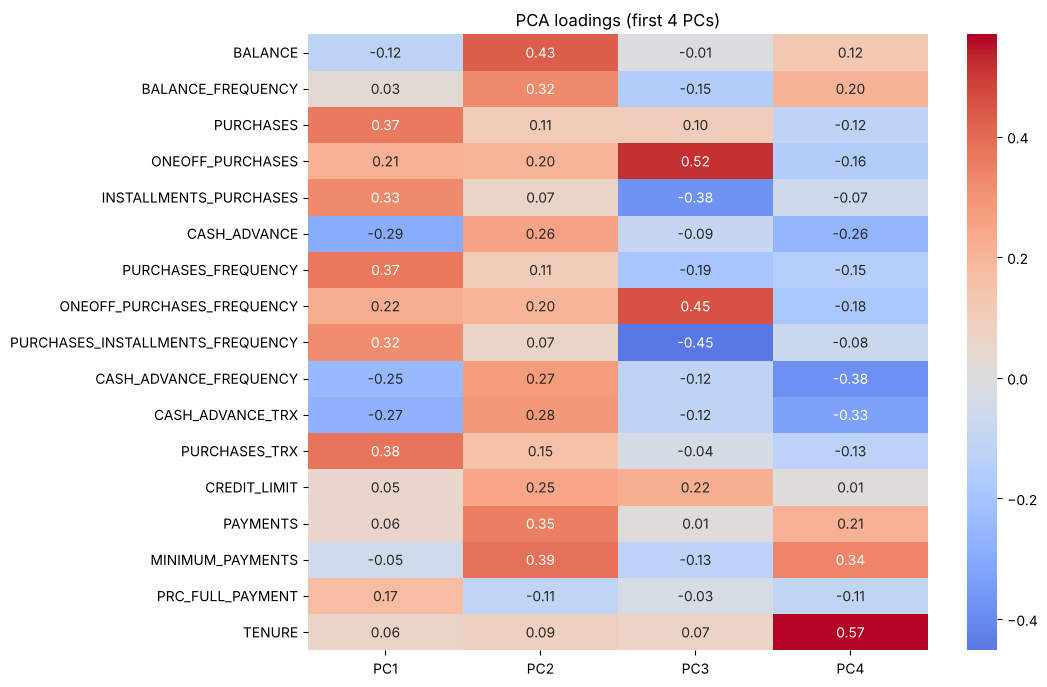

In [33]:
fig, axes = plt.subplots(1, 2, figsize = (20, 7))
for ax, (a, b) in zip(axes, [('PC1', 'PC2'), ('PC1', 'PC3')]):
    sns.scatterplot(x = a, y = b, hue = 'cluster', data = df_pc, palette = 'tab10', s = 12, alpha = 0.6, ax = ax)
    centres = df_pc.groupby('cluster')[[a, b]].mean()
    ax.scatter(centres[a], centres[b], c = 'black', marker = 'X', s = 200)
    for c, row in centres.iterrows():
        ax.annotate(str(c), (row[a], row[b]), fontsize = 14, weight = 'bold', xytext = (6, 6), textcoords = 'offset points')
    ax.set_title('Final clusters in ' + a + ' / ' + b + ' space (X = cluster centre)')
plt.show()

loadings = pd.DataFrame(pca.components_.T, index = data_imputed.columns,
                        columns = ['PC' + str(i + 1) for i in range(pca.n_components_)])
plt.figure(figsize = (10, 8))
sns.heatmap(loadings.iloc[:, :4], annot = True, fmt = '.2f', cmap = 'coolwarm', center = 0)
plt.title('PCA loadings (first 4 PCs)')
plt.show()

**What we see (from the plots and loadings above):**
* **PC1 is a "shopping vs cash-advance" axis.** Purchases, purchase transactions, purchase frequency and instalment purchases load positively; cash advance features load negatively. Moving right means more shopping and less cash borrowing.
* **PC2 is an "account size and activity" axis.** Balance, minimum payments, payments, balance frequency, cash advance and credit limit all load positively. Moving up means a bigger, more active account.
* **Where the clusters sit (cluster centres):** cluster 0 is far left on PC1 (-3.3, cash users who do not shop) and cluster 5 is far right (+3.1, heavy shoppers); cluster 2 is also to the right (+1.7, instalment shoppers). Cluster 1 is far down on PC2 (-3.3, tiny, rarely updated accounts) and cluster 4 is high on PC2 (+2.7, big balances and heavy borrowing). Cluster 3 sits near the middle, which matches its "average, occasional buyer" profile.

The colours overlap in the middle of the picture because PC1 + PC2 hold only about 56% of the variance; the clustering used all 8 PCs, so overlap here does not mean overlap in the full space.

## Step 7: How well-formed is each cluster? (per-cluster silhouette)

The overall silhouette (0.24) is one number for all customers. Computing it **per cluster** tells us which segments are tight and which are blurry. A cluster with a low or negative average silhouette is poorly separated from its neighbours, and statements about it should be made more cautiously.

          mean  share_negative
cluster                       
0        0.363           0.000
1        0.080           0.315
2        0.242           0.017
3        0.208           0.009
4        0.177           0.101
5        0.240           0.003

Overall silhouette: 0.242


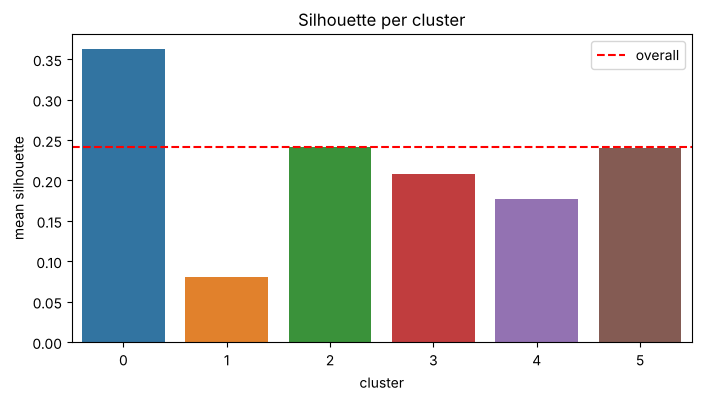

In [34]:
sil = silhouette_samples(data_pca, labels.values)
sil_table = (pd.DataFrame({'cluster': labels.values, 'silhouette': sil})
             .groupby('cluster')['silhouette']
             .agg(mean = 'mean', share_negative = lambda s: (s < 0).mean())
             .round(3))
print(sil_table)
print('\nOverall silhouette:', round(sil.mean(), 3))

plt.figure(figsize = (8, 4))
sns.barplot(x = sil_table.index, y = sil_table['mean'], palette = 'tab10')
plt.axhline(sil.mean(), color = 'red', linestyle = '--', label = 'overall')
plt.ylabel('mean silhouette'); plt.legend(); plt.title('Silhouette per cluster')
plt.show()

**What we see:** cluster 0 is the best-defined group (mean silhouette 0.36, no negative values). Clusters 2, 3 and 5 are moderate (0.21 to 0.24). **Cluster 4 (0.18, about 10% negative) and especially cluster 1 (0.08, about 32% negative)** are fuzzy: many of their customers are almost as close to a neighbouring cluster as to their own. Cluster 1 is the group of low-activity customers, and low activity is a continuum rather than a sharp boundary. Keep this in mind when describing clusters 1 and 4: they are tendencies, not hard categories.

## Step 8: Pair plots on the key features, coloured by cluster

This is the pair plot from the earlier version, but now colouring the points by the **final model's clusters**. We use the six key money features in transformed + standardized units. The diagonal shows each feature's distribution per cluster; the off-diagonal panels show two features at a time. Look for panels where the colours separate into different regions.

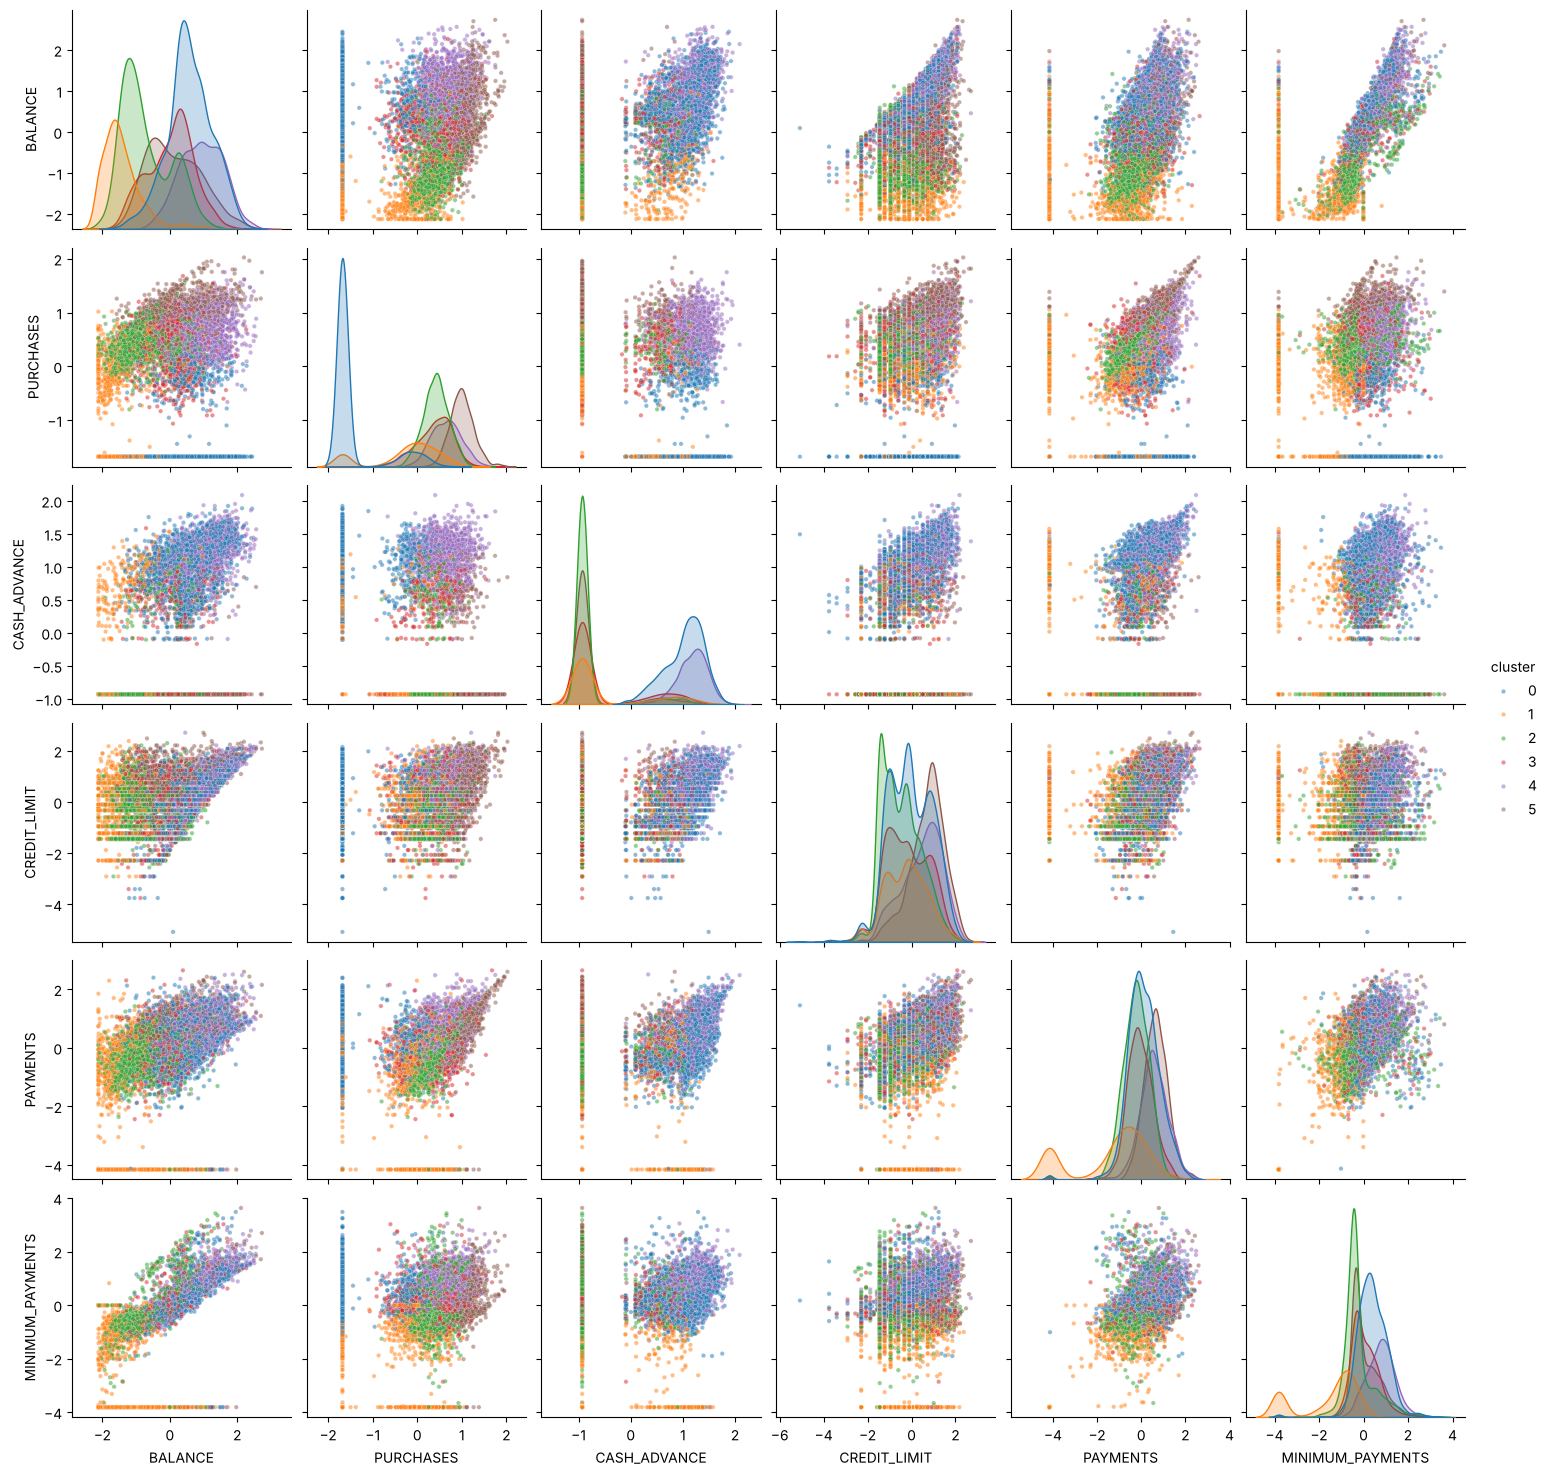

In [35]:
best_cols = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS']
sns.pairplot(df_z[best_cols + ['cluster']], hue = 'cluster', palette = 'tab10',
             plot_kws = {'s': 10, 'alpha': 0.5}, diag_kind = 'kde')
plt.show()

The big pair plot has 36 panels. Next we draw **focused** pair plots that show the pairs that actually separate the clusters: spending vs repayment, borrowing vs balance, and credit limit vs balance (how stretched a customer is).

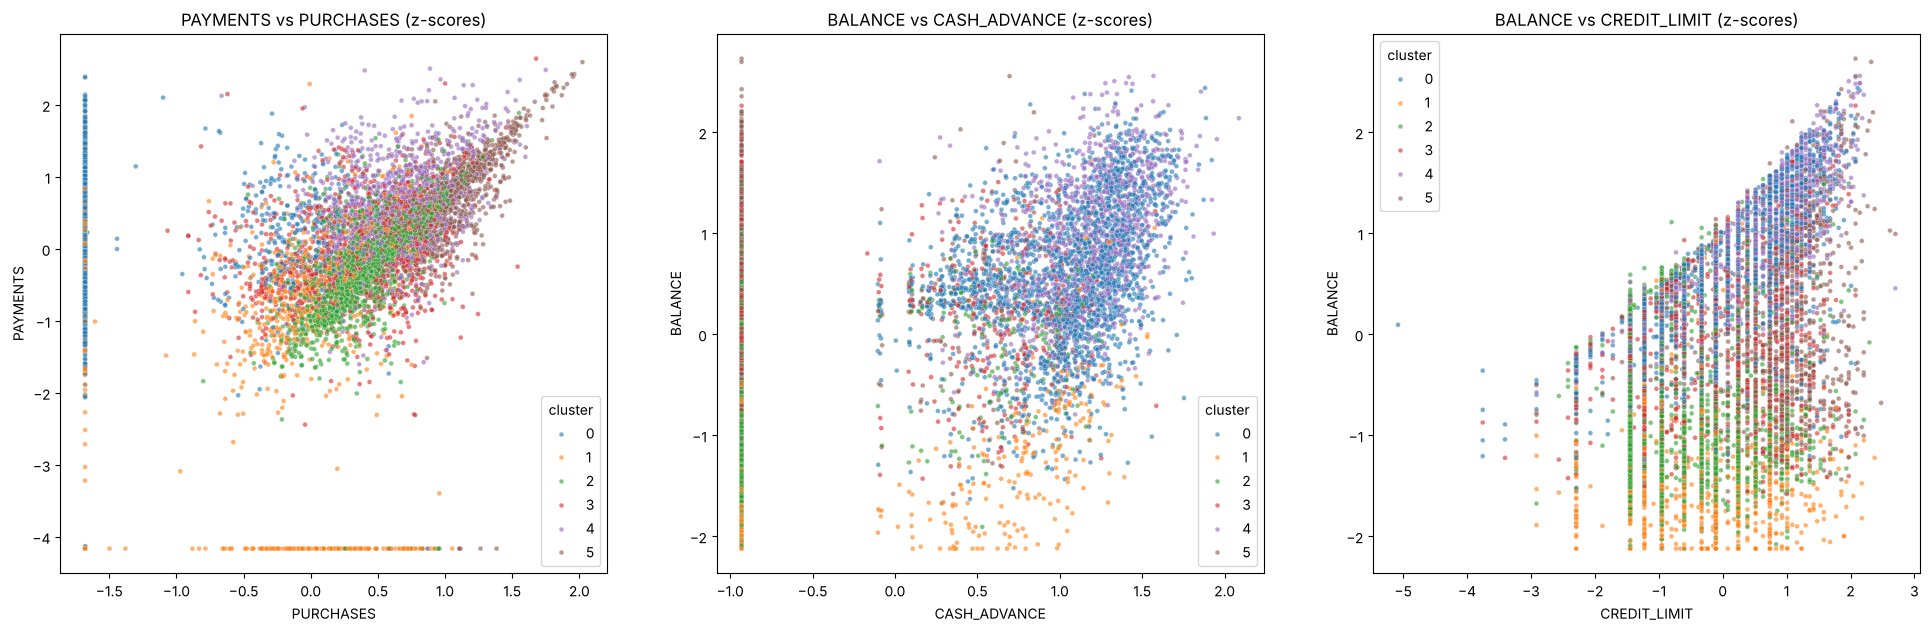

In [36]:
fig, axes = plt.subplots(1, 3, figsize = (24, 7))
for ax, (x, y) in zip(axes, [('PURCHASES', 'PAYMENTS'), ('CASH_ADVANCE', 'BALANCE'), ('CREDIT_LIMIT', 'BALANCE')]):
    sns.scatterplot(x = x, y = y, hue = 'cluster', data = df_z, palette = 'tab10', s = 12, alpha = 0.6, ax = ax)
    ax.set_title(y + ' vs ' + x + ' (z-scores)')
plt.show()

## Step 9: Deep-dive on every cluster

For each cluster we run the same report, so the clusters can be compared fairly. The function below prints:
* the cluster's **size**,
* its **median in original units next to the overall median**, with a ratio (a ratio of 3 means "three times the typical customer"),
* the **features that make it most different** (largest absolute z-scores),

and draws two plots: a bar chart of its z-scores, and a scatter of the cluster (highlighted) against everyone else.

In [37]:
overall_median = df_orig[profile_cols].median()
overall_mean   = df_orig[profile_cols].mean()

def cluster_report(c, scatter_pairs = (('PURCHASES', 'PAYMENTS'), ('CASH_ADVANCE', 'BALANCE'))):
    sub = df_orig[df_orig['cluster'] == c]
    print('=' * 70)
    print('CLUSTER', c, '|', len(sub), 'customers (', round(100 * len(sub) / len(df_orig), 1), '% )')
    print('=' * 70)

    # median and mean vs overall (ratio of 3 = three times the typical customer)
    comp = pd.DataFrame({'cluster median': sub[profile_cols].median(), 'overall median': overall_median,
                         'cluster mean': sub[profile_cols].mean(), 'overall mean': overall_mean})
    comp['median ratio'] = (comp['cluster median'] / comp['overall median'].replace(0, np.nan)).round(2)   # NaN if overall median is 0
    comp['mean ratio'] = (comp['cluster mean'] / comp['overall mean']).round(2)
    display(comp.round(2))

    # what makes this cluster different? (only genuinely above / below average features)
    z = fingerprint[c].sort_values()
    above, below = z[z > 0].tail(4)[::-1], z[z < 0].head(4)
    print('Most ABOVE average :', ', '.join(above.index + ' (+' + above.round(2).astype(str) + ')'))
    print('Most BELOW average :', ', '.join(below.index + ' (' + below.round(2).astype(str) + ')'))

    # plots: z-score bars + highlighted scatters
    fig, axes = plt.subplots(1, 3, figsize = (24, 6))
    fingerprint[c].sort_values().plot.barh(ax = axes[0], color = np.where(fingerprint[c].sort_values() > 0, 'indianred', 'steelblue'))
    axes[0].set_title('Cluster ' + str(c) + ': feature z-scores'); axes[0].axvline(0, color = 'black')
    is_c = (df_z['cluster'] == c).map({True: 'cluster ' + str(c), False: 'others'})
    for ax, (x, y) in zip(axes[1:], scatter_pairs):
        sns.scatterplot(x = df_z[x], y = df_z[y], hue = is_c, palette = {'cluster ' + str(c): 'red', 'others': 'lightgrey'},
                        s = 12, alpha = 0.6, ax = ax)
        ax.set_title(y + ' vs ' + x + ' (z-scores)')
    plt.show()

**Before the per-cluster reports:** the cluster names below are our interpretation of the numbers. Each report follows the same order: size, a median/mean comparison with the overall customer, the most unusual features, and plots. Read the numbers first, then the meaning.

## Cluster 0: The Cash-Advance Users

**2,242 customers (25.1%), the biggest and best-defined group.** Every customer here takes cash advances (median about 1,366, about 4 transactions), and **84% have never bought anything with the card** (median purchases = 0). They carry a median balance of about 1,617 on a limit of about 3,000, so they use about **66% of their limit** (the typical customer uses 30%), and they pay about 822, close to the overall median. None of them pay the full bill (median 0%, mean 3%).

*Meaning:* they use the card as a cash-loan line, not for shopping. Cash advances are expensive for the customer and profitable for the bank, but the pattern also signals financial stress.

*Strategy:* move them towards normal card use (purchase cashback, instalment offers), offer a cheaper personal loan or balance-transfer plan, and monitor repayment closely.

CLUSTER 0 | 2242 customers ( 25.1 % )


,cluster median,overall median,cluster mean,overall mean,median ratio,mean ratio
BALANCE,1617.48,873.39,2333.46,1564.47,1.85,1.49
CREDIT_LIMIT,3000.00,3000.00,4172.36,4494.28,1.00,0.93
UTILISATION,0.66,0.30,0.62,0.39,2.16,1.59
PURCHASES,0.00,361.28,23.94,1003.20,0.00,0.02
ONEOFF_PURCHASES,0.00,38.00,20.90,592.44,0.00,0.04
INSTALLMENTS_PURCHASES,0.00,89.00,3.10,411.07,0.00,0.01
PURCHASES_TRX,0.00,7.00,0.29,14.71,0.00,0.02
PURCHASES_FREQUENCY,0.00,0.50,0.02,0.49,0.00,0.04
CASH_ADVANCE,1365.53,0.00,2101.71,978.87,NaN,2.15
CASH_ADVANCE_TRX,4.00,0.00,6.84,3.25,NaN,2.11


Most ABOVE average : CASH_ADVANCE (+1.02), CASH_ADVANCE_TRX (+0.92), CASH_ADVANCE_FREQUENCY (+0.78), BALANCE (+0.58)
Most BELOW average : PURCHASES (-1.43), PURCHASES_TRX (-1.27), PURCHASES_FREQUENCY (-1.17), INSTALLMENTS_PURCHASES (-1.04)


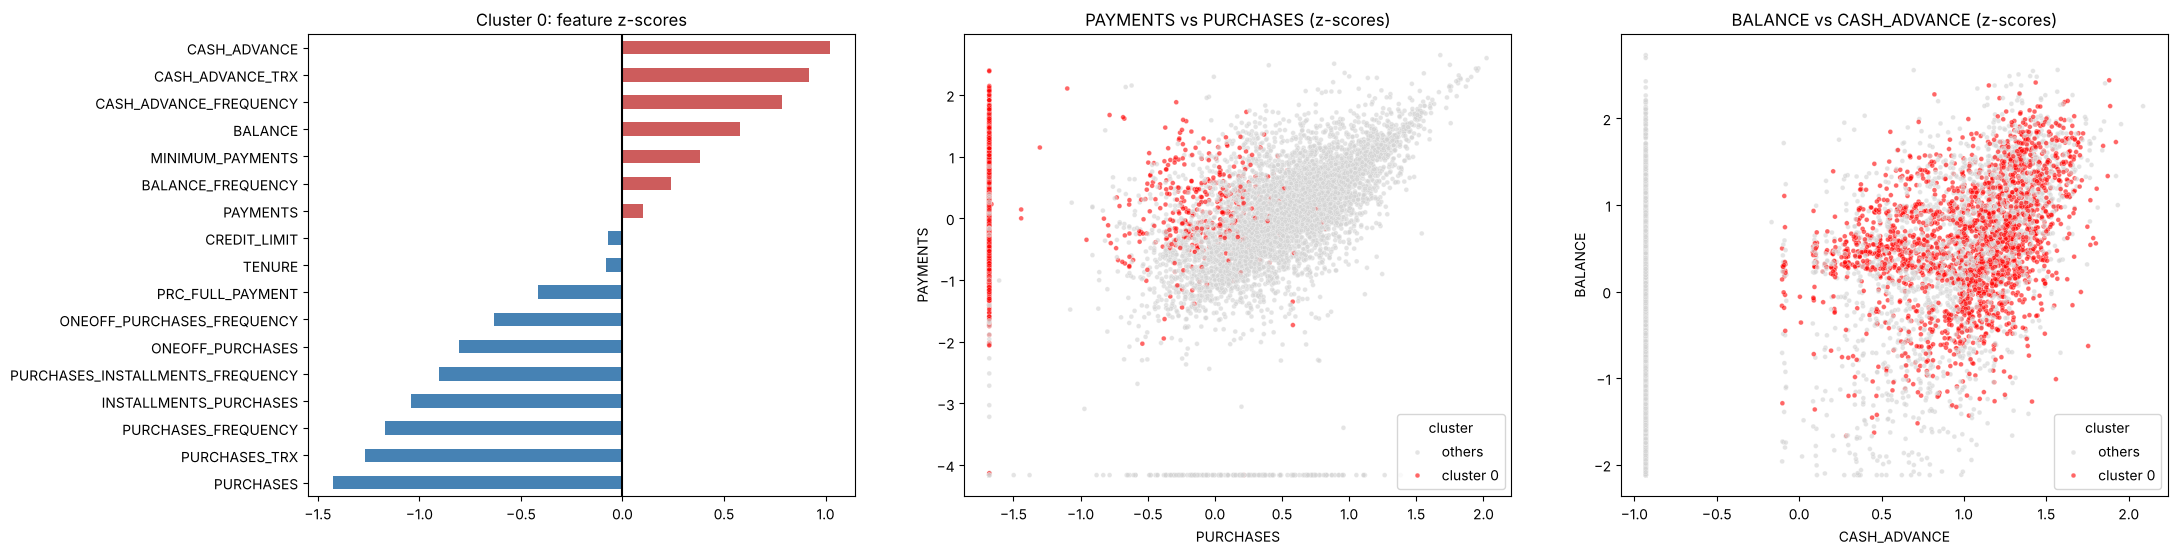

In [38]:
cluster_report(0)

## Cluster 1: The Dormant Accounts

**921 customers (10.3%), the smallest and fuzziest group (silhouette 0.08).** Their **balance is almost never updated** (median balance frequency 0.30; 76% are below 0.5), the median balance is only about 14, purchases are small (median about 111, 2 transactions), payments are about 196 and minimum payments about 70. 23% made no payment at all in six months.

*Meaning:* these are dormant or barely used accounts. They are low risk but also earn the bank almost nothing. Because the group blends smoothly into the other low-activity customers, treat the label as approximate.

*Strategy:* a re-activation campaign (welcome-back offer, small first-purchase reward) and a check on whether the card is still wanted.

CLUSTER 1 | 921 customers ( 10.3 % )


,cluster median,overall median,cluster mean,overall mean,median ratio,mean ratio
BALANCE,14.37,873.39,114.20,1564.47,0.02,0.07
CREDIT_LIMIT,2700.00,3000.00,3555.56,4494.28,0.90,0.79
UTILISATION,0.01,0.30,0.04,0.39,0.02,0.11
PURCHASES,111.30,361.28,230.22,1003.20,0.31,0.23
ONEOFF_PURCHASES,0.00,38.00,147.01,592.44,0.00,0.25
INSTALLMENTS_PURCHASES,0.00,89.00,83.28,411.07,0.00,0.20
PURCHASES_TRX,2.00,7.00,3.22,14.71,0.29,0.22
PURCHASES_FREQUENCY,0.17,0.50,0.22,0.49,0.33,0.46
CASH_ADVANCE,0.00,0.00,227.77,978.87,NaN,0.23
CASH_ADVANCE_TRX,0.00,0.00,0.66,3.25,NaN,0.20


Most ABOVE average : PRC_FULL_PAYMENT (+0.05)
Most BELOW average : BALANCE_FREQUENCY (-2.19), MINIMUM_PAYMENTS (-1.58), BALANCE (-1.42), PAYMENTS (-1.37)


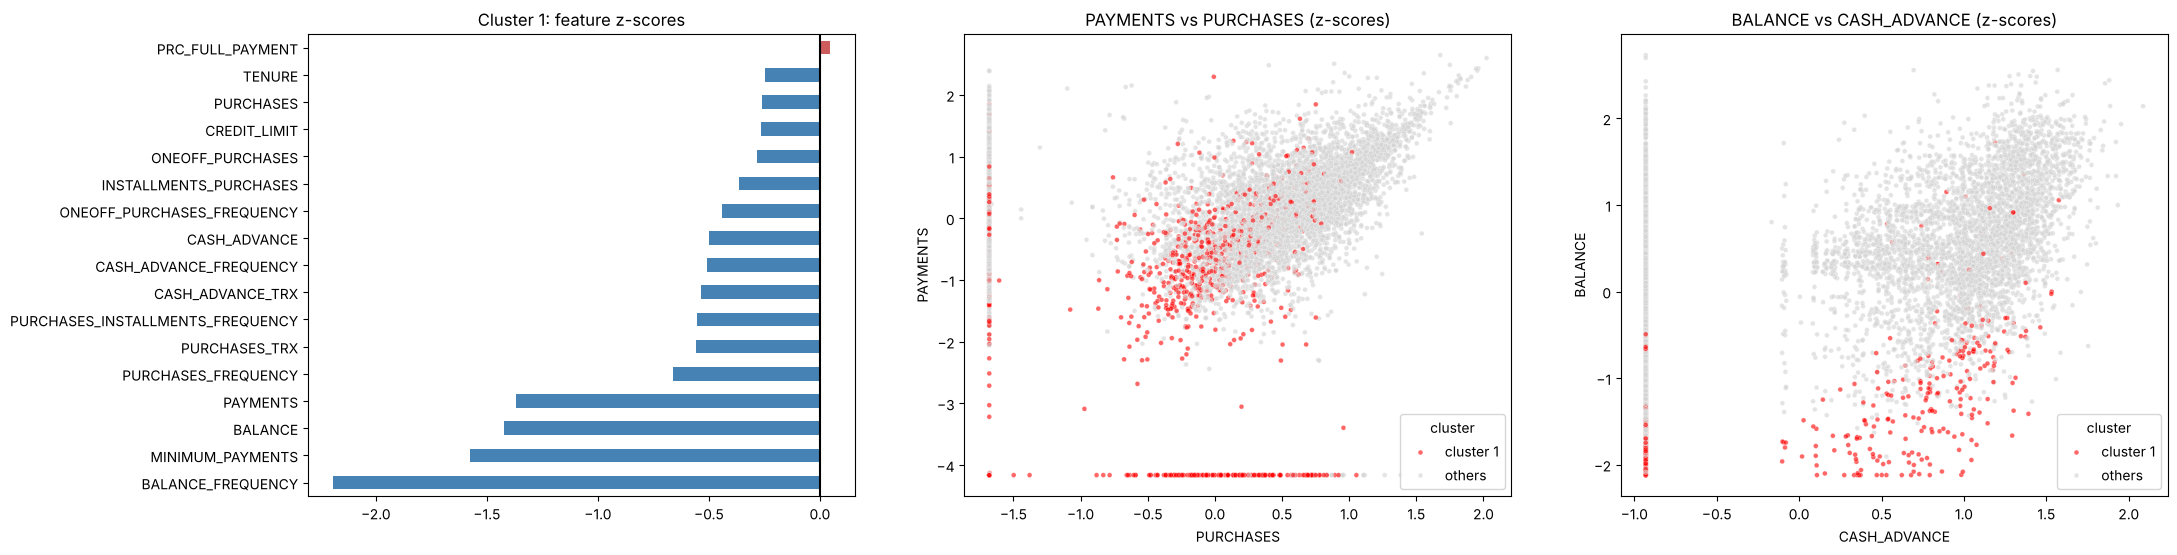

In [39]:
cluster_report(1)

## Cluster 2: The Installment Shoppers

**1,824 customers (20.4%).** They shop in **nearly every period (purchase frequency 0.92)**, mostly through **instalments**: every customer in the group uses instalments, the median instalment spend is about 424 (4.8 times the overall median) and one-off spend is 0. They take almost no cash advances (91% never), keep a tiny balance (median about 95, 5% of the limit) on the lowest limit of all clusters (median about 2,000), and are among the best repayers: they pay the full bill in an average of 32% of cycles.

*Meaning:* low-risk, disciplined, EMI-minded users. The value per customer is modest (purchases about 450).

*Strategy:* EMI and no-cost instalment partnerships, gradual limit increases for good repayers, cross-selling (insurance, rewards cards).

CLUSTER 2 | 1824 customers ( 20.4 % )


,cluster median,overall median,cluster mean,overall mean,median ratio,mean ratio
BALANCE,95.39,873.39,413.24,1564.47,0.11,0.26
CREDIT_LIMIT,2000.00,3000.00,2887.26,4494.28,0.67,0.64
UTILISATION,0.05,0.30,0.23,0.39,0.15,0.59
PURCHASES,450.34,361.28,640.46,1003.20,1.25,0.64
ONEOFF_PURCHASES,0.00,38.00,36.16,592.44,0.00,0.06
INSTALLMENTS_PURCHASES,424.03,89.00,605.22,411.07,4.76,1.47
PURCHASES_TRX,12.00,7.00,14.51,14.71,1.71,0.99
PURCHASES_FREQUENCY,0.92,0.50,0.82,0.49,1.83,1.68
CASH_ADVANCE,0.00,0.00,45.92,978.87,NaN,0.05
CASH_ADVANCE_TRX,0.00,0.00,0.17,3.25,NaN,0.05


Most ABOVE average : PURCHASES_INSTALLMENTS_FREQUENCY (+1.04), INSTALLMENTS_PURCHASES (+0.88), PURCHASES_FREQUENCY (+0.83), PRC_FULL_PAYMENT (+0.56)
Most BELOW average : CASH_ADVANCE (-0.79), CASH_ADVANCE_TRX (-0.72), BALANCE (-0.72), ONEOFF_PURCHASES (-0.72)


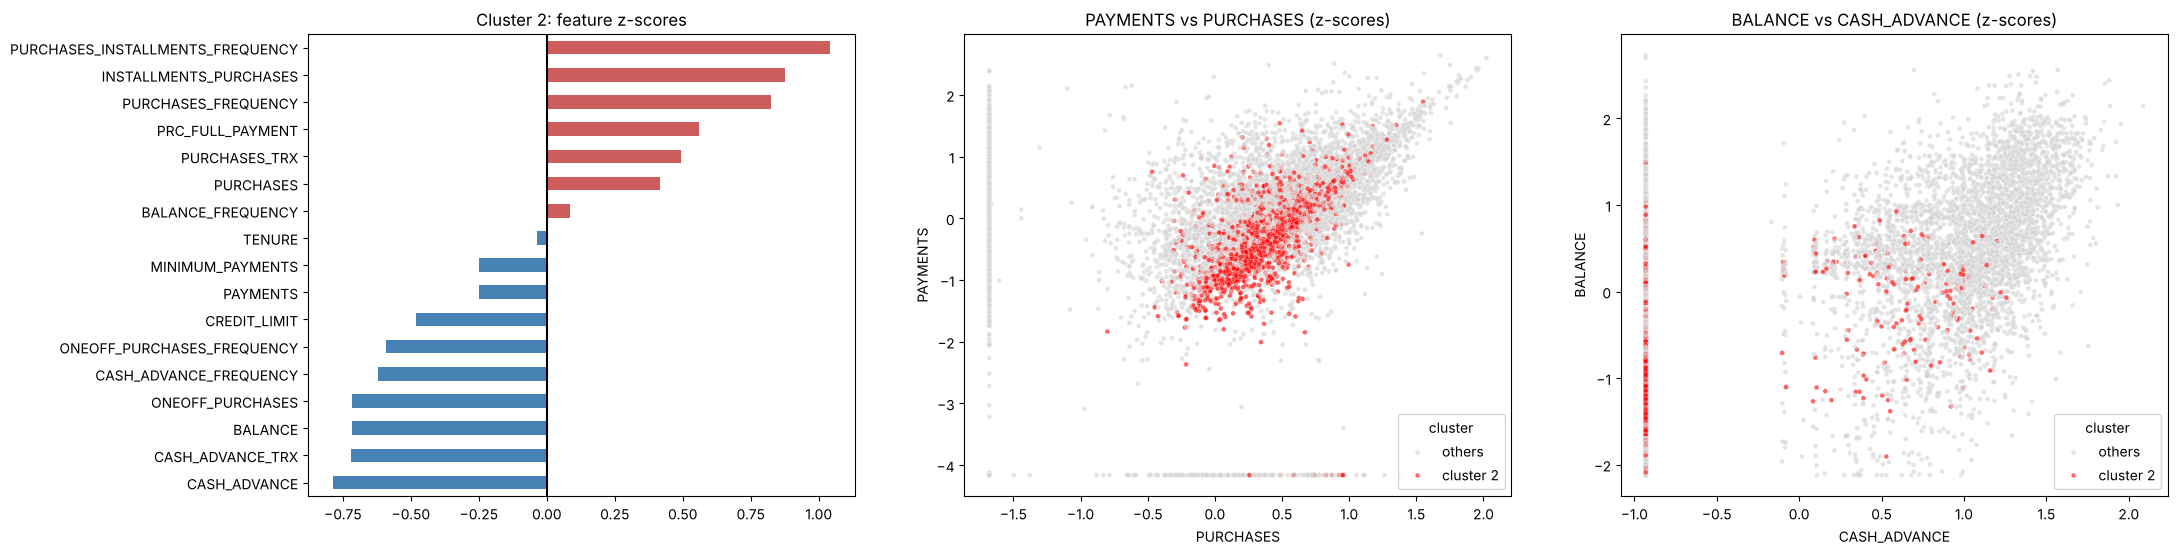

In [40]:
cluster_report(2)

## Cluster 3: The Occasional One-off Buyers

**1,369 customers (15.3%).** They buy **occasionally (purchase frequency 0.33, median 5 transactions) and in one go**: 93% make one-off purchases (median about 400, 10.5 times the overall median) and almost none use instalments (median 0). They take little cash (24% ever), carry a moderate balance (median about 843, 33% of the limit) and pay about 638. They rarely pay in full (mean 6%).

*Meaning:* average, mid-activity customers who use the card for occasional bigger purchases.

*Strategy:* encourage more frequent use with category cashback and offers on larger purchases, and introduce instalment options to increase spending.

CLUSTER 3 | 1369 customers ( 15.3 % )


,cluster median,overall median,cluster mean,overall mean,median ratio,mean ratio
BALANCE,843.36,873.39,1110.18,1564.47,0.97,0.71
CREDIT_LIMIT,2600.00,3000.00,3785.65,4494.28,0.87,0.84
UTILISATION,0.33,0.30,0.42,0.39,1.09,1.07
PURCHASES,466.18,361.28,726.42,1003.20,1.29,0.72
ONEOFF_PURCHASES,400.00,38.00,667.29,592.44,10.53,1.13
INSTALLMENTS_PURCHASES,0.00,89.00,59.48,411.07,0.00,0.14
PURCHASES_TRX,5.00,7.00,7.07,14.71,0.71,0.48
PURCHASES_FREQUENCY,0.33,0.50,0.36,0.49,0.67,0.73
CASH_ADVANCE,0.00,0.00,135.64,978.87,NaN,0.14
CASH_ADVANCE_TRX,0.00,0.00,0.48,3.25,NaN,0.15


Most ABOVE average : ONEOFF_PURCHASES (+0.73), PURCHASES (+0.37), ONEOFF_PURCHASES_FREQUENCY (+0.3), BALANCE_FREQUENCY (+0.18)
Most BELOW average : PURCHASES_INSTALLMENTS_FREQUENCY (-0.72), INSTALLMENTS_PURCHASES (-0.59), CASH_ADVANCE_TRX (-0.57), CASH_ADVANCE (-0.55)


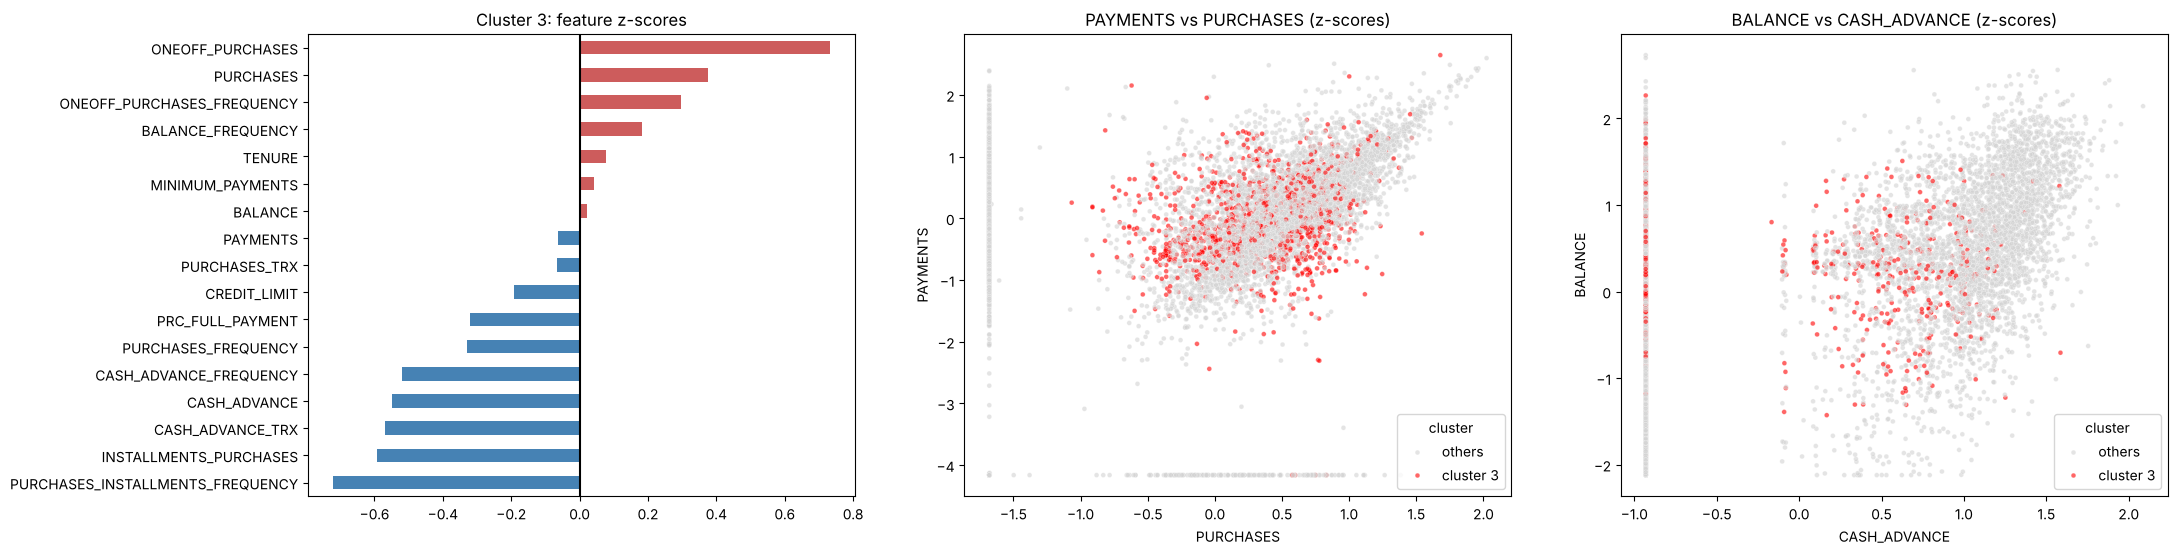

In [41]:
cluster_report(3)

## Cluster 4: The Heavy Borrowers (High Balance, High Risk)

**1,191 customers (13.3%).** The most financially stretched, **and the most active**: the highest balance (median about 2,773, 3.2 times the overall median), the **highest cash advance use (every customer; median about 2,025, 7 transactions)**, solid purchases (median about 909, 2.5 times the overall median), a high limit (about 5,500) but **62% of it used**, the highest minimum payments (about 1,027) and large payments (about 1,810). Almost nobody pays in full (mean 4%). Silhouette 0.18, so the boundary with clusters 0 and 5 is fuzzy.

*Meaning:* heavy revolvers. They generate the most interest and fee income, and also carry the most default risk.

*Strategy:* careful credit-risk monitoring, early-warning payment reminders, limit increases only with a good repayment record, and debt-consolidation or balance-transfer offers to keep them healthy and loyal.

CLUSTER 4 | 1191 customers ( 13.3 % )


,cluster median,overall median,cluster mean,overall mean,median ratio,mean ratio
BALANCE,2772.79,873.39,3526.24,1564.47,3.17,2.25
CREDIT_LIMIT,5500.00,3000.00,6110.12,4494.28,1.83,1.36
UTILISATION,0.62,0.30,0.61,0.39,2.06,1.56
PURCHASES,909.30,361.28,1441.61,1003.20,2.52,1.44
ONEOFF_PURCHASES,403.38,38.00,823.74,592.44,10.62,1.39
INSTALLMENTS_PURCHASES,333.28,89.00,618.13,411.07,3.74,1.50
PURCHASES_TRX,14.00,7.00,23.61,14.71,2.00,1.61
PURCHASES_FREQUENCY,0.75,0.50,0.72,0.49,1.50,1.46
CASH_ADVANCE,2025.44,0.00,2932.47,978.87,NaN,3.00
CASH_ADVANCE_TRX,7.00,0.00,9.99,3.25,NaN,3.07


Most ABOVE average : CASH_ADVANCE_TRX (+1.28), CASH_ADVANCE_FREQUENCY (+1.19), CASH_ADVANCE (+1.18), BALANCE (+0.93)
Most BELOW average : PRC_FULL_PAYMENT (-0.39), TENURE (-0.03)


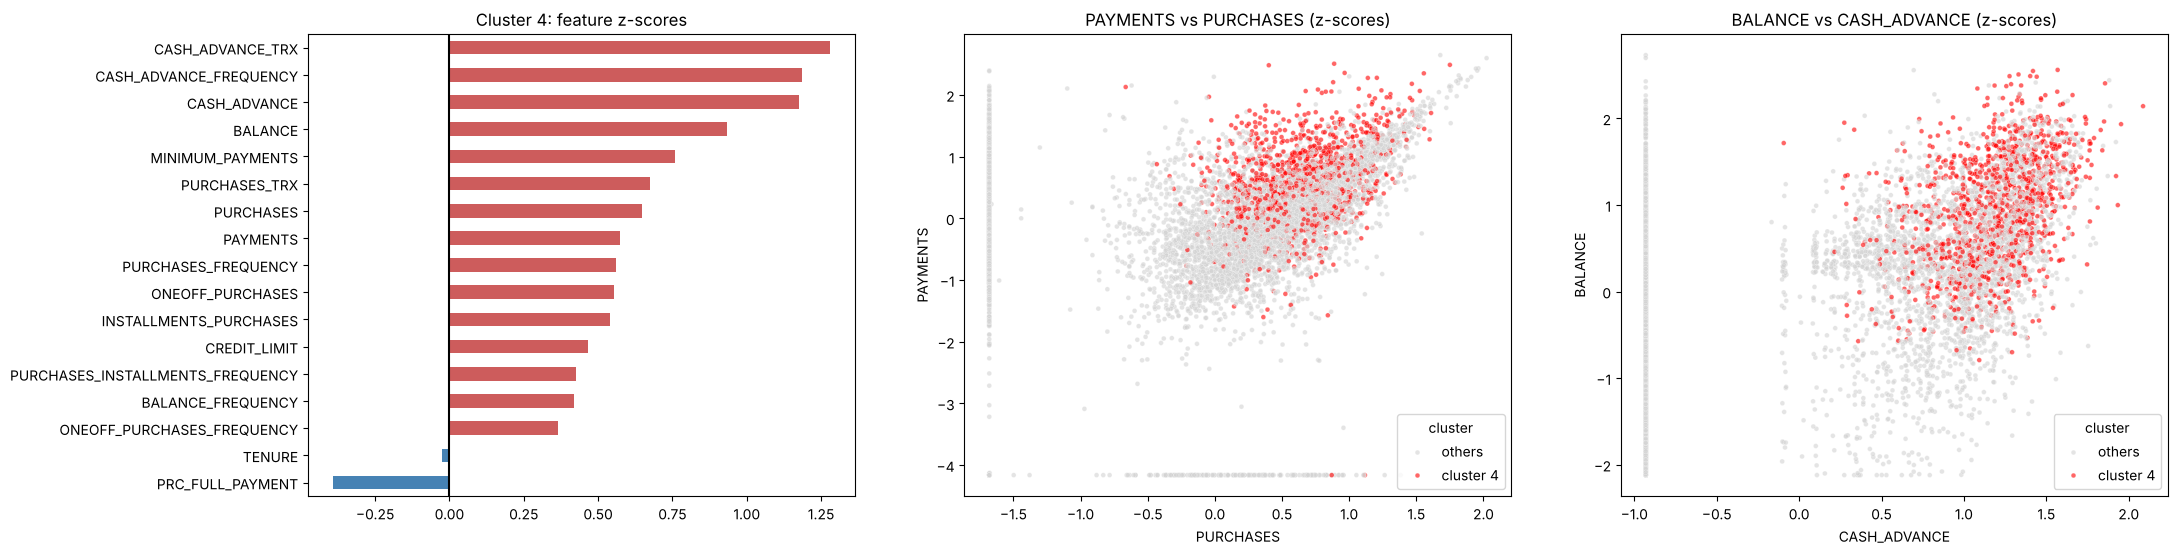

In [42]:
cluster_report(4)

## Cluster 5: The Big Spenders

**1,403 customers (15.7%), the ideal group.** They have the **highest purchases of every kind** (median about 2,391, 6.6 times the overall median; one-off about 1,364 and instalments about 752), shop in every period (frequency 1.0, median 33 transactions), and hold the **highest credit limit (about 6,500) but use only 15% of it**. They almost never take cash advances (88% never), pay about 2,088 (roughly what they spend) and pay the full bill in an average of 32% of cycles.

*Meaning:* affluent, active, low-risk customers who generate fee (interchange) income from heavy spending.

*Strategy:* protect and reward: premium cards, loyalty programmes, travel and lifestyle benefits, priority service, higher limits.

CLUSTER 5 | 1403 customers ( 15.7 % )


,cluster median,overall median,cluster mean,overall mean,median ratio,mean ratio
BALANCE,722.69,873.39,1562.30,1564.47,0.83,1.00
CREDIT_LIMIT,6500.00,3000.00,7033.98,4494.28,2.17,1.57
UTILISATION,0.15,0.30,0.25,0.39,0.49,0.64
PURCHASES,2390.60,361.28,3445.01,1003.20,6.62,3.43
ONEOFF_PURCHASES,1364.34,38.00,2251.97,592.44,35.90,3.80
INSTALLMENTS_PURCHASES,752.46,89.00,1193.04,411.07,8.45,2.90
PURCHASES_TRX,33.00,7.00,45.46,14.71,4.71,3.09
PURCHASES_FREQUENCY,1.00,0.50,0.92,0.49,2.00,1.88
CASH_ADVANCE,0.00,0.00,54.93,978.87,NaN,0.06
CASH_ADVANCE_TRX,0.00,0.00,0.19,3.25,NaN,0.06


Most ABOVE average : ONEOFF_PURCHASES_FREQUENCY (+1.47), PURCHASES_TRX (+1.24), ONEOFF_PURCHASES (+1.22), PURCHASES_FREQUENCY (+1.08)
Most BELOW average : CASH_ADVANCE (-0.75), CASH_ADVANCE_TRX (-0.71), CASH_ADVANCE_FREQUENCY (-0.61)


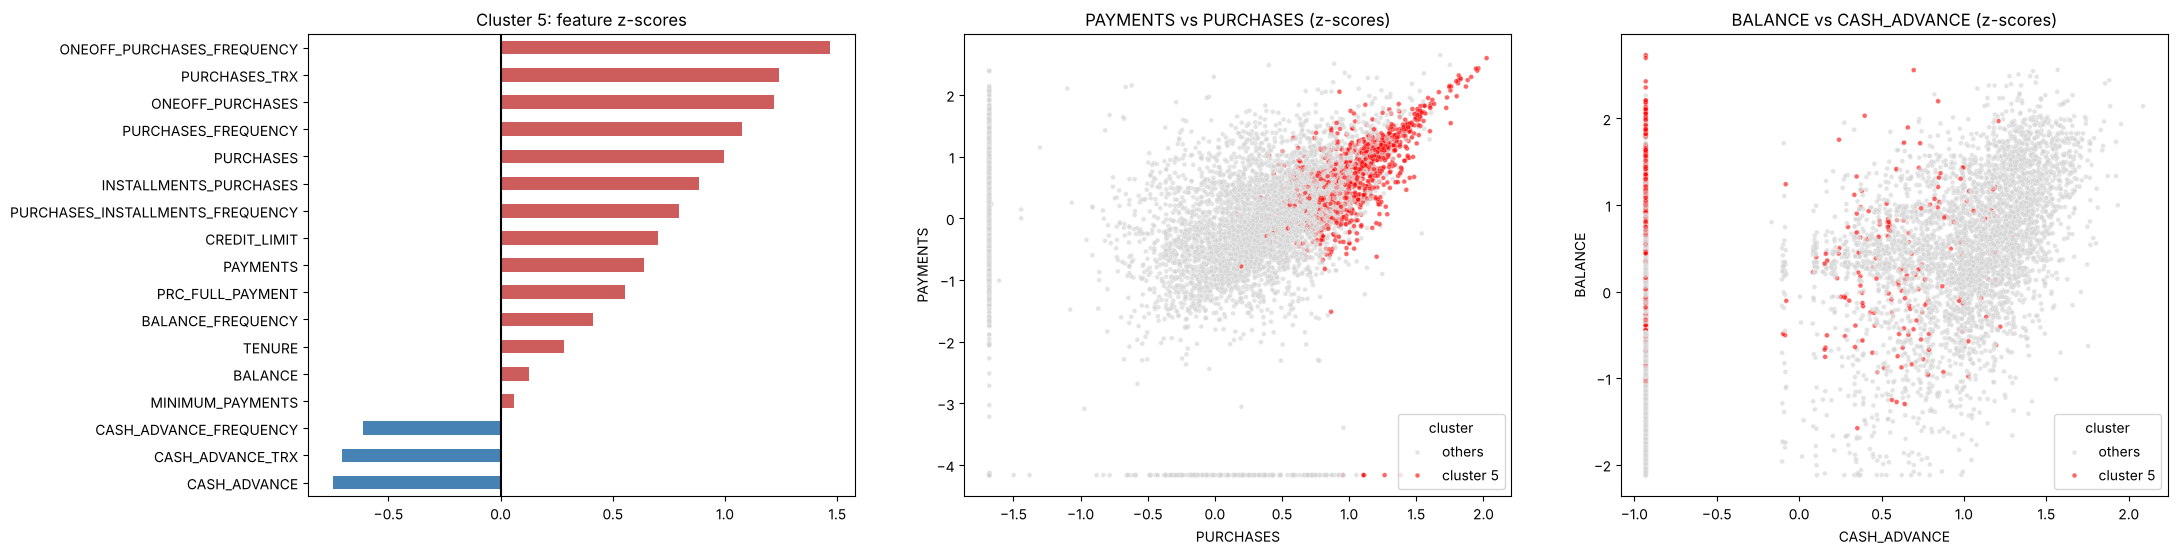

In [43]:
cluster_report(5)

# Summary and Possible Marketing Strategy (Final Model: K-Means + PCA, 6 clusters)

Our final model groups the 8,950 customers into six behavioural segments. Ordered from the lowest to the highest average purchases:

| Cluster | Name | Customers | Defining behaviour | Value / risk | Suggested strategy |
| --- | --- | --- | --- | --- | --- |
| 0 | Cash-Advance Users | 2,242 (25.1%) | Cash advances, almost no purchases, 66% of the limit used | Profitable but risky | Shift to purchases, cheaper loan, monitor |
| 1 | Dormant Accounts | 921 (10.3%) | Balance rarely updated, tiny balance and payments | Low value, low risk | Re-activation campaign |
| 2 | Installment Shoppers | 1,824 (20.4%) | Frequent instalment purchases, low balance, pays in full often | Low risk, moderate value | EMI partnerships, gradual limit increases |
| 3 | Occasional One-off Buyers | 1,369 (15.3%) | Infrequent, one-off purchases | Moderate | Offers on bigger purchases, add instalment options |
| 4 | Heavy Borrowers | 1,191 (13.3%) | Highest balance and cash advances, 62% utilised, still buys | High revenue, highest risk | Risk monitoring, consolidation offers |
| 5 | Big Spenders | 1,403 (15.7%) | Highest purchases, high limit, 15% utilised, no cash advances | Highest value, low risk | Loyalty and premium products |

**Key takeaways**
* **Spend and borrow are two different behaviours.** Clusters 0 and 4 borrow (cash advances); clusters 2, 3 and 5 spend. Cluster 4 does both, which is what makes it the riskiest and the most profitable.
* **Retain the Big Spenders (cluster 5)**, they are the most valuable and safest group.
* **Grow the middle:** clusters 2 and 3 are healthy customers whose spending can be increased with targeted offers.
* **Watch the borrowers (clusters 0 and 4):** nearly 40% of customers rely on cash advances. This is profitable but needs risk monitoring and, ethically, support rather than only upselling.
* **Re-activate the Dormant Accounts (cluster 1)** cheaply, or review whether they should stay open.

# Conclusion

In this project we performed data preprocessing (median / zero-aware imputation and skewness correction with a Yeo-Johnson transform on `BALANCE` and log transforms on the other skewed features), looked at the feature correlations, and showed that K-Means on all 17 features performs poorly (silhouette about 0.22). We then applied PCA keeping 90% of the variance (8 components), which gave more balanced and better-separated clusters, compared K-Means with Agglomerative clustering, and chose **K-Means with 6 clusters on the PCA data** as the final model.

The exploratory analysis was carried out on **the clusters of that final model**: cluster sizes, a profile table in real units, a z-score fingerprint heatmap, box plots, PCA-space plots with loadings, per-cluster silhouette, pair plots and a one-by-one report on each cluster. This produced six interpretable segments (Cash-Advance Users, Dormant Accounts, Installment Shoppers, Occasional One-off Buyers, Heavy Borrowers and Big Spenders) and a marketing action for each.

**Limitations to keep in mind:**
* The overall silhouette is moderate (about 0.24), so the segments overlap; clusters 1 and 4 are the fuzziest (per-cluster silhouette 0.08 and 0.18).
* The cluster names and strategies are our interpretation of the numbers, not something the algorithm produced.
* Cluster numbers follow the order of average purchases, and the results depend on the random seed (42) and library versions.

Possible next steps: try other values of k, add ratio features (utilisation, payment-to-minimum ratio), and test whether the clusters predict outcomes such as late payments if that data becomes available.

This project is also my first try on the business side of Data Science, and how we can use Machine Learning to solve practical, real life issues.